In [1488]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from scipy.stats import binomtest
import statsmodels.api as sm
import scipy.stats as st
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import lilliefors
import scikit_posthocs as sp
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson



epa_cartest = pd.read_excel("25-testcar-2026-01-21.xlsx")
epa_cartest.info()

<class 'pandas.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   str    
 2   Veh Mfr Code                    4287 non-null   str    
 3   Represented Test Veh Make       4287 non-null   str    
 4   Represented Test Veh Model      4287 non-null   str    
 5   Test Vehicle ID                 4287 non-null   str    
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   str    
 9   Vehicle Type                    4287 non-null   str    
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     4287 non-null

# EDA y Limpieza

## Limpieza inicial de columnas

In [1489]:
categorias_delete_list = ["Vehicle Manufacturer Name", "Tested Transmission Type Code", "Drive System Code",
                          "Drive System Code", "Transmission Overdrive Code", 
                          "Shift Indicator Light Use Cd", "Test Procedure Cd",
                          "Test Fuel Type Cd", "Aftertreatment Device Cd",
                          "Model Year", "Engine Code", "Police - Emergency Vehicle?",
                          "FE_UNIT", "Aftertreatment Device Cd"
                        ]

epa_cartest_clean = epa_cartest.drop(columns=categorias_delete_list)

In [1490]:
epa_cartest_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 55 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Veh Mfr Code                    4287 non-null   str    
 1   Represented Test Veh Make       4287 non-null   str    
 2   Represented Test Veh Model      4287 non-null   str    
 3   Test Vehicle ID                 4287 non-null   str    
 4   Test Veh Configuration #        4287 non-null   int64  
 5   Test Veh Displacement (L)       4287 non-null   float64
 6   Actual Tested Testgroup         4287 non-null   str    
 7   Vehicle Type                    4287 non-null   str    
 8   Rated Horsepower                4287 non-null   int64  
 9   # of Cylinders and Rotors       3617 non-null   float64
 10  Tested Transmission Type        4287 non-null   str    
 11  # of Gears                      4287 non-null   int64  
 12  Transmission Lockup?            4287 non-null

## Exploracion de valores nulos

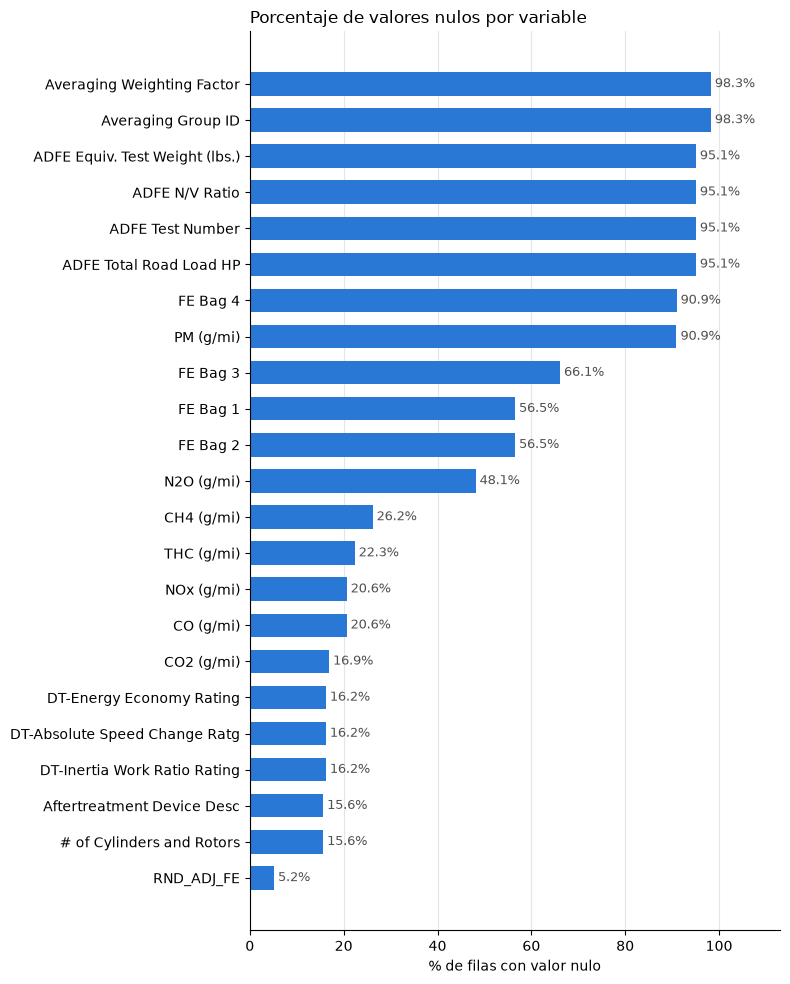

In [1491]:
# Porcentaje de nulos por variable (solo las que tienen alguno), ordenado
nulos = (epa_cartest_clean.isna().mean() * 100).loc[lambda s: s > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 0.38 * len(nulos) + 1.2))
ax.barh(nulos.index, nulos.values, color="#2a78d6", height=0.65)

# Valor al final de cada barra
for y, v in enumerate(nulos.values):
    ax.text(v, y, f" {v:.1f}%", va="center", fontsize=9, color="#52514e")

ax.set_title("Porcentaje de valores nulos por variable", loc="left")
ax.set_xlabel("% de filas con valor nulo")
ax.set_xlim(0, nulos.max() * 1.15)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [1492]:
categorias_nulos = ["Averaging Weighting Factor", "Averaging Group ID", "ADFE Total Road Load HP",
                      "ADFE Equiv. Test Weight (lbs.)", "ADFE N/V Ratio", "ADFE Test Number",
                      "FE Bag 1", "FE Bag 2", "FE Bag 3", "FE Bag 4"
                    ]

epa_cartest_clean = epa_cartest_clean.drop(columns=categorias_nulos)

## Eliminacion de variables no utilizadas en hipotesis

### Variables de configuracion de test

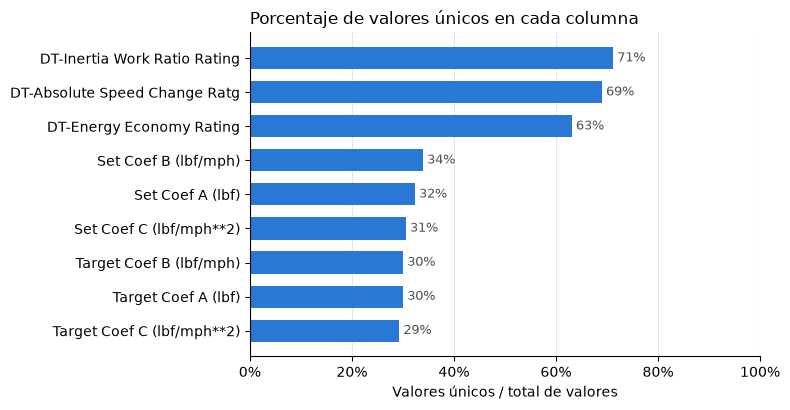

In [1493]:
columnas_DT_Coef = ["DT-Inertia Work Ratio Rating", "DT-Absolute Speed Change Ratg", "DT-Energy Economy Rating",
                    "Target Coef A (lbf)", "Target Coef B (lbf/mph)", "Target Coef C (lbf/mph**2)",
                    "Set Coef A (lbf)", "Set Coef B (lbf/mph)", "Set Coef C (lbf/mph**2)"]

# Fracción de valores únicos sobre el total de valores no nulos
frac_unicos = (epa_cartest_clean[columnas_DT_Coef].nunique() / epa_cartest_clean[columnas_DT_Coef].notna().sum()).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(frac_unicos.index, frac_unicos.values, color="#2a78d6", height=0.65)
for y, v in enumerate(frac_unicos.values):
    ax.text(v, y, f" {v:.0%}", va="center", fontsize=9, color="#52514e")

ax.set_title("Porcentaje de valores únicos en cada columna", loc="left")
ax.set_xlabel("Valores únicos / total de valores")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [1494]:
epa_cartest_clean = epa_cartest_clean.drop(columns=columnas_DT_Coef)

### Variables "Transmission Overdrive Desc" y "Shift Indicator Light"

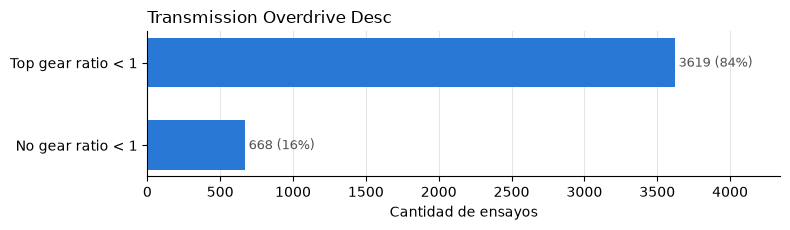

In [1495]:
conteo = epa_cartest_clean["Transmission Overdrive Desc"].value_counts().sort_values()
porc = conteo / conteo.sum()

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.barh(conteo.index, conteo.values, color="#2a78d6", height=0.6)
for y, (v, p) in enumerate(zip(conteo.values, porc.values)):
    ax.text(v, y, f" {v} ({p:.0%})", va="center", fontsize=9, color="#52514e")

ax.set_title("Transmission Overdrive Desc", loc="left")
ax.set_xlabel("Cantidad de ensayos")
ax.set_xlim(0, conteo.max() * 1.2)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

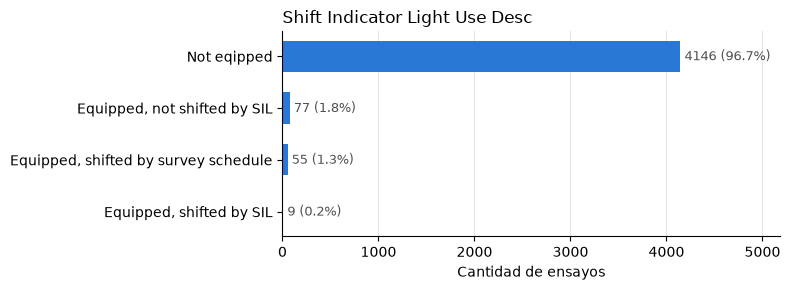

In [1496]:
conteo = epa_cartest_clean["Shift Indicator Light Use Desc"].value_counts().sort_values()
porc = conteo / conteo.sum()

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(conteo.index, conteo.values, color="#2a78d6", height=0.6)
for y, (v, p) in enumerate(zip(conteo.values, porc.values)):
    ax.text(v, y, f" {v} ({p:.1%})", va="center", fontsize=9, color="#52514e")

ax.set_title("Shift Indicator Light Use Desc", loc="left")
ax.set_xlabel("Cantidad de ensayos")
ax.set_xlim(0, conteo.max() * 1.25)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## Exploracion y limpieza de variables de hipotesis

### Test Veh Displacement (L)

#### Limpieza

In [1497]:
values_to_replace = [0.001, 99.999, 0.010, 99.990, 1.000]

condicion = (epa_cartest_clean["Test Fuel Type Description"] == "Electricity") & (epa_cartest_clean["Test Veh Displacement (L)"].isin(values_to_replace))

epa_cartest_clean.loc[condicion, "Test Veh Displacement (L)"] = np.nan

In [1498]:
epa_cartest_clean["Test Veh Displacement (L)"].describe()

count    3633.000000
mean        2.861324
std         1.126258
min         0.001000
25%         2.000000
50%         2.500000
75%         3.445000
max         7.993000
Name: Test Veh Displacement (L), dtype: float64

#### Grafico

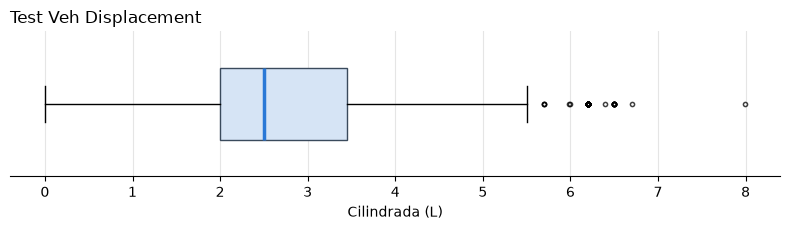

In [1499]:
datos = epa_cartest_clean["Test Veh Displacement (L)"].dropna()

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.boxplot(datos, orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#d6e4f5", edgecolor="#3a4a5c"),
           medianprops=dict(color="#2a78d6", linewidth=2.5),
           flierprops=dict(marker="o", markersize=3, alpha=0.5))
ax.set_yticks([])
ax.set_title("Test Veh Displacement", loc="left")
ax.set_xlabel("Cilindrada (L)")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

### # of Cylinders and Rotors

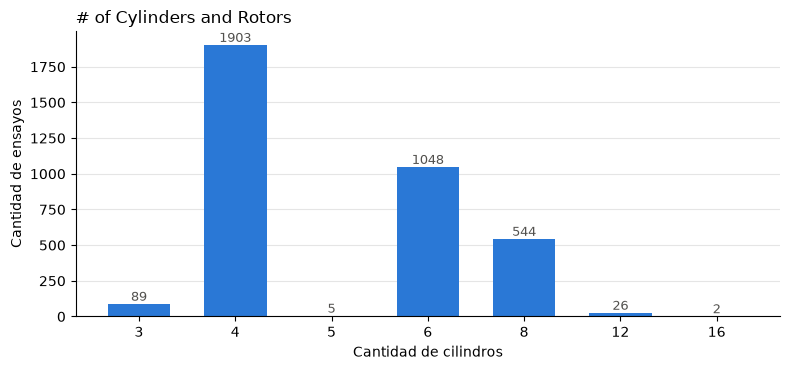

In [1500]:
conteo = epa_cartest_clean["# of Cylinders and Rotors"].value_counts().sort_index()
etiquetas = conteo.index.astype(int).astype(str)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(etiquetas, conteo.values, color="#2a78d6", width=0.65)
for x, v in zip(etiquetas, conteo.values):
    ax.text(x, v, f"{v}", ha="center", va="bottom", fontsize=9, color="#52514e")
ax.set_title("# of Cylinders and Rotors", loc="left")
ax.set_xlabel("Cantidad de cilindros")
ax.set_ylabel("Cantidad de ensayos")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### RND_ADJ_FE

#### LImpieza

In [1501]:
epa_cartest_clean["RND_ADJ_FE"].value_counts().sort_index(ascending=False)

RND_ADJ_FE
10000.0     8
4599.1      1
4595.3      1
999.0      14
207.0       1
           ..
9.4         1
9.2         1
8.3         1
8.0         1
0.0         2
Name: count, Length: 788, dtype: int64

In [1502]:
umbral = 207.0
epa_cartest_clean.loc[epa_cartest_clean["RND_ADJ_FE"] > umbral, "RND_ADJ_FE"] = np.nan

In [1503]:
epa_cartest_clean["RND_ADJ_FE"].describe()

count    4042.000000
mean       39.820980
std        28.407734
min         0.000000
25%        24.300000
50%        32.800000
75%        43.400000
max       207.000000
Name: RND_ADJ_FE, dtype: float64

#### Graficos

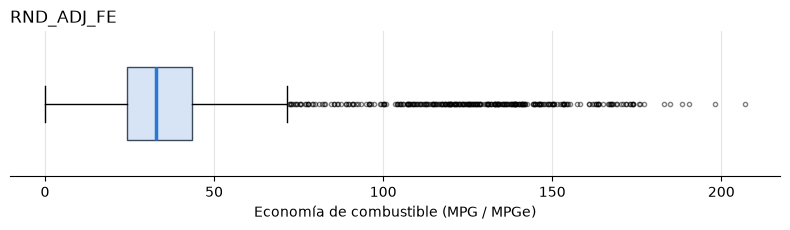

In [1504]:
datos = epa_cartest_clean["RND_ADJ_FE"].dropna()

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.boxplot(datos, orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#d6e4f5", edgecolor="#3a4a5c"),
           medianprops=dict(color="#2a78d6", linewidth=2.5),
           flierprops=dict(marker="o", markersize=3, alpha=0.5))
ax.set_yticks([])
ax.set_title("RND_ADJ_FE", loc="left")
ax.set_xlabel("Economía de combustible (MPG / MPGe)")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

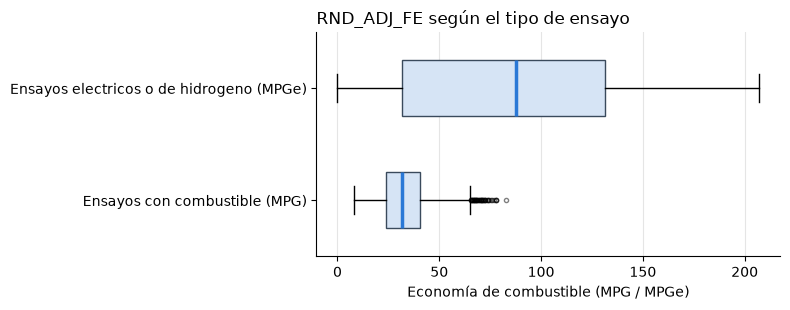

In [1505]:
es_electrico = ((epa_cartest_clean["Test Category"] == "CD") |
                epa_cartest_clean["Test Fuel Type Description"].isin(["Electricity", "Hydrogen 5"]))

grupos = {
    "Ensayos con combustible (MPG)": epa_cartest_clean.loc[~es_electrico, "RND_ADJ_FE"].dropna(),
    "Ensayos electricos o de hidrogeno (MPGe)": epa_cartest_clean.loc[es_electrico, "RND_ADJ_FE"].dropna(),
}

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.boxplot(list(grupos.values()), orientation="horizontal", widths=0.5, patch_artist=True,
           tick_labels=list(grupos.keys()),
           boxprops=dict(facecolor="#d6e4f5", edgecolor="#3a4a5c"),
           medianprops=dict(color="#2a78d6", linewidth=2.5),
           flierprops=dict(marker="o", markersize=3, alpha=0.5))
ax.set_title("RND_ADJ_FE según el tipo de ensayo", loc="left")
ax.set_xlabel("Economía de combustible (MPG / MPGe)")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Rated Horsepower

In [1506]:
epa_cartest_clean["Rated Horsepower"].describe()

count    4287.000000
mean      340.698157
std       175.121581
min         1.000000
25%       201.000000
50%       305.000000
75%       409.000000
max      1948.000000
Name: Rated Horsepower, dtype: float64

#### Limpieza

In [1507]:
epa_cartest_clean[epa_cartest_clean["Rated Horsepower"] < 80]["Rated Horsepower"]

845     1
846     1
847     1
856     1
857     1
858     1
3711    1
3712    1
Name: Rated Horsepower, dtype: int64

In [1508]:
epa_cartest_clean[epa_cartest_clean["Rated Horsepower"] < 90]

,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Description,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,Test Procedure Description,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,Aftertreatment Device Desc,Averaging Method Cd,Averging Method Desc
663,CRX,Fiat,500e,K3FGE3812,0,NaN,RCRXV00.05P6,Car,87,NaN,Other,1,N,"2-Wheel Drive, Front",Top gear ratio < 1,3250,9.59,136.8,Not eqipped,RCRX10083817,MFR,No,Multi-Cycle Test (MCT),Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.3,NaN,N,No averaging
664,CRX,Fiat,500e,K3FGE3812,0,NaN,RCRXV00.05P6,Car,87,NaN,Other,1,N,"2-Wheel Drive, Front",Top gear ratio < 1,3250,9.59,136.8,Not eqipped,RCRX10083998,MFR,No,Charge Depleting Highway,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.1,NaN,N,No averaging
845,FMX,Ford,BRONCO SPORT 4WD,SRE00010,0,1.500,SFMXT01.52X2,Truck,1,3.0,Automatic,8,Y,Part-time 4-Wheel Drive,Top gear ratio < 1,3750,3.80,28.6,Not eqipped,SFMX10087831,MFR,No,Federal fuel 2-day exhaust (w/can load),Tier 2 Cert Gasoline,FTP,0.012590,0.238834,269.8,0.004268,NaN,0.003846,0.0009,32.8,Three-way catalyst,N,No averaging
846,FMX,Ford,BRONCO SPORT 4WD,SRE00010,0,1.500,SFMXT01.52X2,Truck,1,3.0,Automatic,8,Y,Part-time 4-Wheel Drive,Top gear ratio < 1,3750,3.80,28.6,Not eqipped,SFMX10087833,MFR,No,US06,Tier 2 Cert Gasoline,US06,0.022528,1.557010,333.3,0.029784,NaN,0.007586,0.0049,26.5,Three-way catalyst,N,No averaging
847,FMX,Ford,BRONCO SPORT 4WD,SRE00010,0,1.500,SFMXT01.52X2,Truck,1,3.0,Automatic,8,Y,Part-time 4-Wheel Drive,Top gear ratio < 1,3750,3.80,28.6,Not eqipped,SFMX10088030,MFR,No,HWFE,Tier 2 Cert Gasoline,HWY,0.012328,0.260223,181.2,0.002531,NaN,0.003051,0.0018,49.1,Three-way catalyst,N,No averaging
856,FMX,Ford,BRONCO SPORT SASQUATCH,SRE00024,0,1.500,SFMXT01.52X2,Truck,1,3.0,Automatic,8,Y,"2-Wheel Drive, Front",Top gear ratio < 1,4000,3.80,28.1,Not eqipped,SFMX10088283,MFR,No,Federal fuel 2-day exhaust (w/can load),Tier 2 Cert Gasoline,FTP,0.014585,0.310000,288.7,0.006995,NaN,0.004100,0.0020,30.8,Three-way catalyst,N,No averaging
857,FMX,Ford,BRONCO SPORT SASQUATCH,SRE00024,0,1.500,SFMXT01.52X2,Truck,1,3.0,Automatic,8,Y,"2-Wheel Drive, Front",Top gear ratio < 1,4000,3.80,28.1,Not eqipped,SFMX10088284,MFR,No,HWFE,Tier 2 Cert Gasoline,HWY,0.017439,0.350152,205.4,0.014157,NaN,0.003525,0.0058,43.3,Three-way catalyst,N,No averaging
858,FMX,Ford,BRONCO SPORT SASQUATCH,SRE00024,0,1.500,SFMXT01.52X2,Truck,1,3.0,Automatic,8,Y,"2-Wheel Drive, Front",Top gear ratio < 1,4000,3.80,28.1,Not eqipped,SFMX10088285,MFR,No,US06,Tier 2 Cert Gasoline,US06,0.017532,1.503700,365.5,0.024821,NaN,0.005626,NaN,24.2,Three-way catalyst,N,No averaging
3711,TYX,TOYOTA,MIRAI,21-JD2F,0,0.001,MTYXV00.0DA7,Car,1,NaN,Continuously Variable,1,N,"2-Wheel Drive, Rear",No gear ratio < 1,4500,0.00,0.0,Not eqipped,MTYX10066646,MFR,No,HWFE,Hydrogen 5,HWY,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.1,NaN,N,No averaging
3712,TYX,TOYOTA,MIRAI,21-JD2F,0,0.001,MTYXV00.0DA7,Car,1,NaN,Continuously Variable,1,N,"2-Wheel Drive, Rear",No gear ratio < 1,4500,0.00,0.0,Not eqipped,MTYX10066647,MFR,No,CVS 75 and later (w/o can. load),Hydrogen 5,FTP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.0,NaN,N,No averaging


In [1509]:
epa_cartest_clean.loc[epa_cartest_clean["Rated Horsepower"] < 10, "Rated Horsepower"] = np.nan
epa_cartest_clean["Rated Horsepower"].describe()

count    4279.000000
mean      341.333255
std       174.667461
min        87.000000
25%       201.000000
50%       305.000000
75%       412.000000
max      1948.000000
Name: Rated Horsepower, dtype: float64

#### Grafico

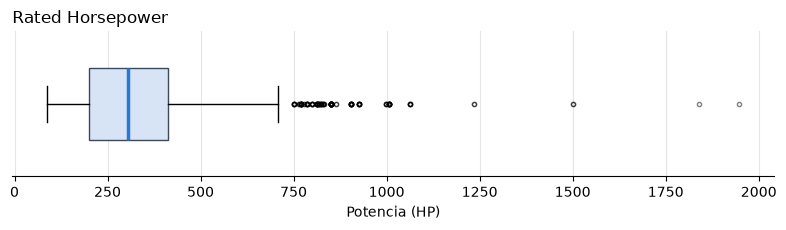

In [1510]:
datos = epa_cartest_clean["Rated Horsepower"].dropna()

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.boxplot(datos, orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#d6e4f5", edgecolor="#3a4a5c"),
           medianprops=dict(color="#2a78d6", linewidth=2.5),
           flierprops=dict(marker="o", markersize=3, alpha=0.5))
ax.set_yticks([])
ax.set_title("Rated Horsepower", loc="left")
ax.set_xlabel("Potencia (HP)")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

### Tested Transmission Type

#### Limpieza

In [1511]:
epa_cartest_clean["Tested Transmission Type"].value_counts()

Tested Transmission Type
Automatic                                                            1639
Semi-Automatic                                                       1220
Continuously Variable                                                 490
Automated Manual- Selectable (e.g. Automated Manual with paddles)     485
Selectable Continuously Variable (e.g. CVT with paddles)              171
Manual                                                                128
Other                                                                 102
Automated Manual                                                       52
Name: count, dtype: int64

In [1512]:
epa_cartest_clean[epa_cartest_clean["Tested Transmission Type"] == "Other"].tail(52)

,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Veh Configuration #,Test Veh Displacement (L),Actual Tested Testgroup,Vehicle Type,Rated Horsepower,# of Cylinders and Rotors,Tested Transmission Type,# of Gears,Transmission Lockup?,Drive System Description,Transmission Overdrive Desc,Equivalent Test Weight (lbs.),Axle Ratio,N/V Ratio,Shift Indicator Light Use Desc,Test Number,Test Originator,Analytically Derived FE?,Test Procedure Description,Test Fuel Type Description,Test Category,THC (g/mi),CO (g/mi),CO2 (g/mi),NOx (g/mi),PM (g/mi),CH4 (g/mi),N2O (g/mi),RND_ADJ_FE,Aftertreatment Device Desc,Averaging Method Cd,Averging Method Desc
3353,TSL,Tesla,"Model S Plaid (21"" Wheels)",ST324-517994,0,NaN,RTSLV00.0L3S,Car,1006.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5000,1.00,90.3,Not eqipped,RTSL10083103,MFR,No,Charge Depleting UDDS,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,133.5,NaN,N,No averaging
3354,TSL,Tesla,"Model S Plaid (21"" Wheels)",ST324-517994,0,NaN,RTSLV00.0L3S,Car,1006.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5000,1.00,90.3,Not eqipped,RTSL10083104,MFR,No,Charge Depleting Highway,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,122.4,NaN,N,No averaging
3355,TSL,Tesla,"Model S Plaid (21"" Wheels)",ST324-517994,0,NaN,RTSLV00.0L3S,Car,1006.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5000,1.00,90.3,Not eqipped,RTSL10083105,MFR,No,CVS 75 and later (w/o can. load),Electricity,FTP,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,N,No averaging
3356,TSL,Tesla,"Model S Plaid (21"" Wheels)",ST324-517994,0,NaN,RTSLV00.0L3S,Car,1006.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5000,1.00,90.3,Not eqipped,RTSL10083106,MFR,No,HWFE,Electricity,HWY,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,N,No averaging
3357,TSL,Tesla,"Model S Plaid (21"" Wheels)",ST324-517994,0,NaN,RTSLV00.0L3S,Car,1006.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5000,1.00,90.3,Not eqipped,RTSL10083109,MFR,No,SC03,Electricity,SC03,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,N,No averaging
3358,TSL,Tesla,"Model S Plaid (21"" Wheels)",ST324-517994,0,NaN,RTSLV00.0L3S,Car,1006.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5000,1.00,90.3,Not eqipped,RTSL10087905,MFR,No,Charge Depleting 20 Degree F FTP,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.1,NaN,N,No averaging
3359,TSL,Tesla,Model X Long Range,XD224-419185,0,NaN,RTSLV00.0L2X,Car,658.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5500,1.00,102.7,Not eqipped,RTSL10083679,MFR,No,Charge Depleting UDDS,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,146.5,NaN,N,No averaging
3360,TSL,Tesla,Model X Long Range,XD224-419185,0,NaN,RTSLV00.0L2X,Car,658.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5500,1.00,102.7,Not eqipped,RTSL10083680,MFR,No,Charge Depleting Highway,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,134.0,NaN,N,No averaging
3361,TSL,Tesla,"Model X Plaid (20"" Wheels)",XT324-405823,0,NaN,RTSLV00.0L3X,Car,925.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5500,1.00,85.9,Not eqipped,RTSL10083073,MFR,No,CVS 75 and later (w/o can. load),Electricity,FTP,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,N,No averaging
3362,TSL,Tesla,"Model X Plaid (20"" Wheels)",XT324-405823,0,NaN,RTSLV00.0L3X,Car,925.0,NaN,Other,1,N,4-Wheel Drive,No gear ratio < 1,5500,1.00,85.9,Not eqipped,RTSL10083074,MFR,No,Charge Depleting Highway,Electricity,CD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,127.0,NaN,N,No averaging


In [1513]:
mapping = {
    'Other' : 'Automatic'
}

epa_cartest_clean["Tested Transmission Type"] = epa_cartest_clean["Tested Transmission Type"].replace(mapping)

epa_cartest_clean["Tested Transmission Type"].value_counts()

Tested Transmission Type
Automatic                                                            1741
Semi-Automatic                                                       1220
Continuously Variable                                                 490
Automated Manual- Selectable (e.g. Automated Manual with paddles)     485
Selectable Continuously Variable (e.g. CVT with paddles)              171
Manual                                                                128
Automated Manual                                                       52
Name: count, dtype: int64

#### Grafico

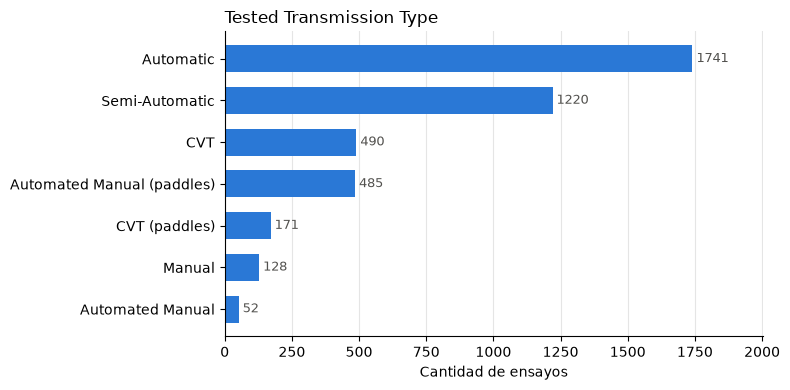

In [1514]:
# Copia del dataset para no modificar el original
epa_cartest_transmision = epa_cartest_clean.copy()

# Nombres cortos para mayor legibilidad
mapeo_transmision = {
    "Automated Manual- Selectable (e.g. Automated Manual with paddles)": "Automated Manual (paddles)",
    "Selectable Continuously Variable (e.g. CVT with paddles)": "CVT (paddles)",
    "Continuously Variable": "CVT",
}
epa_cartest_transmision["Tested Transmission Type"] = epa_cartest_transmision["Tested Transmission Type"].replace(mapeo_transmision)

conteo = epa_cartest_transmision["Tested Transmission Type"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(conteo) + 1.2))
ax.barh(conteo.index, conteo.values, color="#2a78d6", height=0.65)
for y, v in enumerate(conteo.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9, color="#52514e")
ax.set_title("Tested Transmission Type", loc="left")
ax.set_xlabel("Cantidad de ensayos")
ax.set_xlim(0, conteo.max() * 1.15)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### CO (g/mi)

In [1515]:
epa_cartest_clean["CO (g/mi)"].isna().sum()

np.int64(884)

#### Grafico

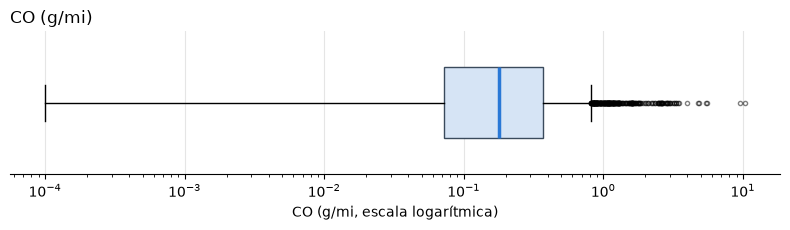

In [1516]:
datos = epa_cartest_clean["CO (g/mi)"].dropna()
datos = datos[datos > 0]  # la escala log no admite ceros

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.boxplot(datos, orientation="horizontal", widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#d6e4f5", edgecolor="#3a4a5c"),
           medianprops=dict(color="#2a78d6", linewidth=2.5),
           flierprops=dict(marker="o", markersize=3, alpha=0.5))
ax.set_xscale("log")
ax.set_yticks([])
ax.set_title("CO (g/mi)", loc="left")
ax.set_xlabel("CO (g/mi, escala logarítmica)")
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout()
plt.show()

### Drive System Description

In [1517]:
epa_cartest_clean["Drive System Description"].value_counts()

Drive System Description
All Wheel Drive            1459
2-Wheel Drive, Front       1393
2-Wheel Drive, Rear         957
4-Wheel Drive               405
Part-time 4-Wheel Drive      73
Name: count, dtype: int64

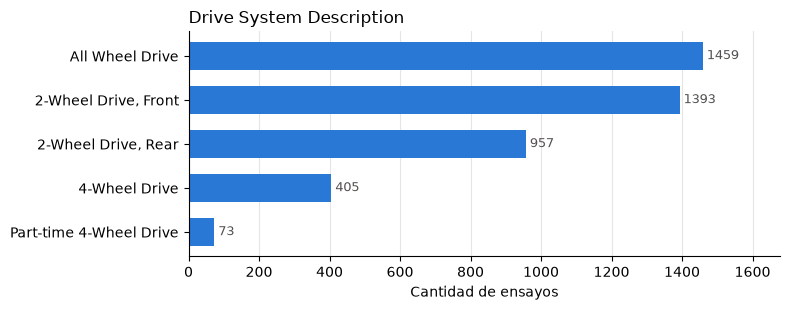

In [1518]:
conteo = epa_cartest_clean["Drive System Description"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(conteo) + 1.2))
ax.barh(conteo.index, conteo.values, color="#2a78d6", height=0.65)
for y, v in enumerate(conteo.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9, color="#52514e")
ax.set_title("Drive System Description", loc="left")
ax.set_xlabel("Cantidad de ensayos")
ax.set_xlim(0, conteo.max() * 1.15)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Test Category

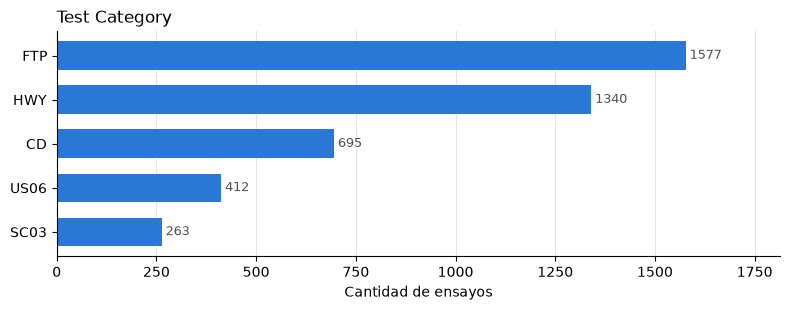

In [1519]:
conteo = epa_cartest_clean["Test Category"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(conteo) + 1.2))
ax.barh(conteo.index, conteo.values, color="#2a78d6", height=0.65)
for y, v in enumerate(conteo.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9, color="#52514e")
ax.set_title("Test Category", loc="left")
ax.set_xlabel("Cantidad de ensayos")
ax.set_xlim(0, conteo.max() * 1.15)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Test Procedure Description

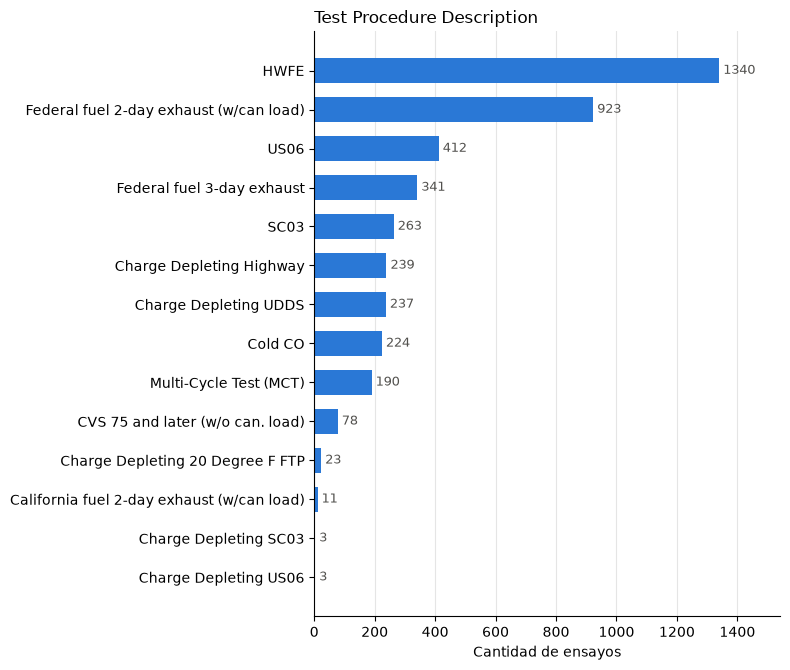

In [1520]:
conteo = epa_cartest_clean["Test Procedure Description"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(conteo) + 1.2))
ax.barh(conteo.index, conteo.values, color="#2a78d6", height=0.65)
for y, v in enumerate(conteo.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9, color="#52514e")
ax.set_title("Test Procedure Description", loc="left")
ax.set_xlabel("Cantidad de ensayos")
ax.set_xlim(0, conteo.max() * 1.15)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Test Fuel Type Description

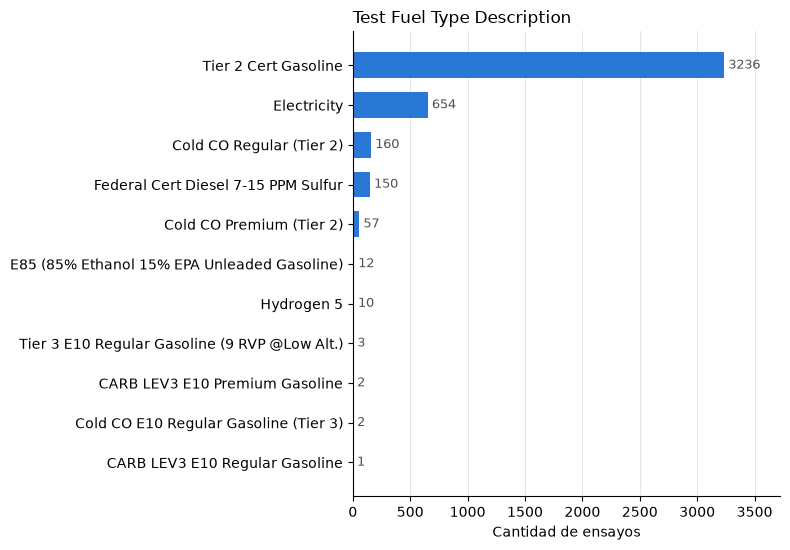

In [1521]:
conteo = epa_cartest_clean["Test Fuel Type Description"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 0.4 * len(conteo) + 1.2))
ax.barh(conteo.index, conteo.values, color="#2a78d6", height=0.65)
for y, v in enumerate(conteo.values):
    ax.text(v, y, f" {v}", va="center", fontsize=9, color="#52514e")
ax.set_title("Test Fuel Type Description", loc="left")
ax.set_xlabel("Cantidad de ensayos")
ax.set_xlim(0, conteo.max() * 1.15)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Filtrado para hipotesis

## Filtrado para hipotesis 4a, 4b, 4c

### Generacion de UID

In [1522]:
epa_cartest_uid = epa_cartest_clean.copy()
epa_cartest_uid["UID"] = epa_cartest_uid["Veh Mfr Code"] + "-" + epa_cartest_uid["Test Vehicle ID"] + "-" + epa_cartest_uid["Test Veh Configuration #"].astype(str)

### Filtrado de filas ADFE

In [1523]:
only_gasoline = epa_cartest_uid.copy()
only_gasoline = only_gasoline[epa_cartest_uid["Analytically Derived FE?"] == "No"]

### Filtrado por tests de conduccion urbana

In [1524]:
only_gasoline = only_gasoline[only_gasoline["Test Procedure Description"] != "Cold CO"]

### Filtrado de vehiculos a combustion

##### Filtrado por condiciones de test

In [1525]:
# crear columna de si test es CD
only_gasoline["is_CD"] = only_gasoline["Test Category"] == "CD"
include = ["Electricity", "Hydrogen 5"]
# crear columna de si la fila es de hidrogeno o electrica
only_gasoline["is_ElectricOrHydrogenFueled"] = only_gasoline["Test Fuel Type Description"].isin(include)
# crear columna de si la configuracion del vehiculo de la fila tiene algun test CD
only_gasoline["config_has_any_cd"] = only_gasoline.groupby("UID", dropna=False)["is_CD"].transform('any')
# crear columna de si la configuracion del vehiculo de la fila es basada en electricidad o hidrogeno
only_gasoline["config_is_electric_or_hydrogen_based"] = only_gasoline.groupby("UID", dropna=False)["is_ElectricOrHydrogenFueled"].transform('any')
#filtrado para quedarnos con las configuraciones que no tengan ningula fila con test de tipo CD o con tipo de combustible electricidad o hidrogeno
only_gasoline = only_gasoline[~(only_gasoline["config_has_any_cd"] | only_gasoline["config_is_electric_or_hydrogen_based"])]
only_gasoline["UID"].value_counts()

UID
GMX-53KPRVT288-6      14
GMX-30KLSVT494-0      12
GMX-366MDN4388-0      11
GMX-15E2S3V006-2       9
GMX-30KPPV1976-6       9
                      ..
HNX-ESMC2C-2           1
HNX-ESMC2C-4           1
HNX-ESMC3C-1           1
JLX-3ESTT003-2         1
LTX-EDV-25-EVSA6-0     1
Name: count, Length: 1014, dtype: int64

In [1526]:
only_gasoline["Test Fuel Type Description"].value_counts()

Test Fuel Type Description
Tier 2 Cert Gasoline                             2743
Federal Cert Diesel 7-15 PPM Sulfur               141
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

#### Filtrado por denominacion de vehiculo

In [1527]:
long_previa = len(only_gasoline)
patron = r"\bhybrid\b|\b[PFM]?HEV\b"
mask = only_gasoline["Represented Test Veh Model"].str.contains(patron, case=False, na=False)
uids_drop = only_gasoline.loc[mask, "UID"]
only_gasoline = only_gasoline[~only_gasoline["UID"].isin(uids_drop)].reset_index(drop=True)
print(long_previa - len(only_gasoline), "filas dropeadas,", len(only_gasoline), "filas remanentes")

205 filas dropeadas, 2697 filas remanentes


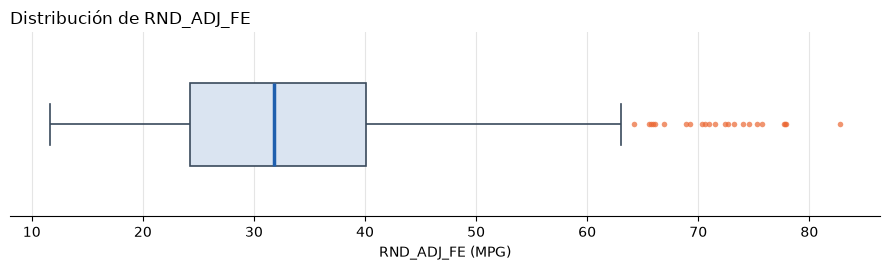

In [1528]:
fig, ax = plt.subplots(figsize=(9, 2.8))
sns.boxplot(data=only_gasoline, x="RND_ADJ_FE", width=0.45, color="#d6e4f5", linecolor="#3a4a5c",
            linewidth=1.2, medianprops=dict(color="#1f5fae", linewidth=2.5),
            flierprops=dict(marker="o", markersize=4, markerfacecolor="#eb6834",
                            markeredgecolor="none", alpha=0.7), ax=ax)
ax.set_title("Distribución de RND_ADJ_FE", loc="left", fontsize=12)
ax.set_xlabel("RND_ADJ_FE (MPG)")
ax.set_yticks([])
ax.grid(axis="x", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

#### Filtrado por cociente autopista/ciudad

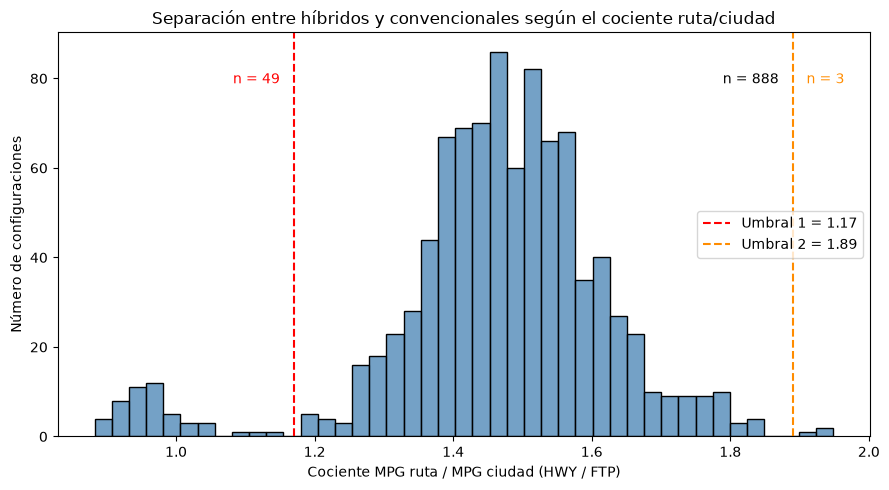

In [1529]:
UMBRAL1 = 1.17
UMBRAL2 = 1.89

ciudad = only_gasoline[only_gasoline["Test Category"] == "FTP"].groupby("UID")["RND_ADJ_FE"].median()
ruta   = only_gasoline[only_gasoline["Test Category"] == "HWY"].groupby("UID")["RND_ADJ_FE"].median()
cociente = (ruta / ciudad).dropna()

n_bajo  = (cociente < UMBRAL1).sum()
n_medio = ((cociente >= UMBRAL1) & (cociente < UMBRAL2)).sum()
n_alto  = (cociente >= UMBRAL2).sum()

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(cociente, binwidth=0.025, color="steelblue", ax=ax)
ax.axvline(UMBRAL1, color="red", ls="--", label=f"Umbral 1 = {UMBRAL1}")
ax.axvline(UMBRAL2, color="darkorange", ls="--", label=f"Umbral 2 = {UMBRAL2}")

ax.set_xlabel("Cociente MPG ruta / MPG ciudad (HWY / FTP)")
ax.set_ylabel("Número de configuraciones")
ax.set_title("Separación entre híbridos y convencionales según el cociente ruta/ciudad")

y_txt = ax.get_ylim()[1] * 0.9
ax.text(UMBRAL1 - 0.02, y_txt, f"n = {n_bajo}", ha="right", va="top", color="red")
ax.text(UMBRAL2 - 0.02, y_txt, f"n = {n_medio}", ha="right", va="top")
ax.text(UMBRAL2 + 0.02, y_txt, f"n = {n_alto}", ha="left", va="top", color="darkorange")

ax.legend(loc="center right")
plt.tight_layout()
plt.show()

In [1530]:
cols = ["Represented Test Veh Make", "Represented Test Veh Model",
        "Tested Transmission Type", "Drive System Description",
        "Test Veh Displacement (L)", "Rated Horsepower"]

def tabla_cola(uids):
    return (only_gasoline[only_gasoline["UID"].isin(uids)]
            .groupby("UID")[cols].first()
            .assign(ciudad=ciudad, ruta=ruta, cociente=cociente)
            .sort_values("cociente"))

uids_bajo = cociente[cociente < UMBRAL1].index
uids_alto = cociente[cociente >= UMBRAL2].index

print(f"Debajo de umbral 1 ({UMBRAL1}): {len(uids_bajo)} configuraciones")
display(tabla_cola(uids_bajo))

print(f"Encima de umbral 2 ({UMBRAL2}): {len(uids_alto)} configuraciones")
display(tabla_cola(uids_alto))

Debajo de umbral 1 (1.17): 49 configuraciones


,Represented Test Veh Make,Represented Test Veh Model,Tested Transmission Type,Drive System Description,Test Veh Displacement (L),Rated Horsepower,ciudad,ruta,cociente
UID,,,,,,,,,
HNX-EP9F2C-1,HONDA,CR-V AWD,Continuously Variable,"2-Wheel Drive, Front",2.000,145.0,56.1,49.50,0.882353
FMX-SRA00005-0,Ford,Maverick,Continuously Variable,"2-Wheel Drive, Front",2.500,162.0,61.2,54.70,0.893791
HNX-EP9F1C-2,HONDA,CR-V FWD,Continuously Variable,"2-Wheel Drive, Front",2.000,145.0,61.1,54.75,0.896072
TYX-25-MA2H-0,LEXUS,UX 300h,Continuously Variable,"2-Wheel Drive, Front",1.987,150.0,65.6,59.00,0.899390
TYX-25-MA1H-1,LEXUS,UX 300h AWD,Continuously Variable,"2-Wheel Drive, Front",1.987,150.0,64.2,58.60,0.912773
HNX-ESMC2C-1,HONDA,CIVIC 4Dr,Continuously Variable,"2-Wheel Drive, Front",2.000,141.0,75.3,68.90,0.915007
TYX-22-AZ3H-1,LEXUS,NX 350h AWD,Continuously Variable,"2-Wheel Drive, Front",2.487,189.0,56.8,52.10,0.917254
HNX-EPNH1C-0,HONDA,ACCORD SPORT/TOURING,Continuously Variable,"2-Wheel Drive, Front",2.000,146.0,65.9,60.50,0.918058
HNX-ESMC3C-0,HONDA,CIVIC 5Dr,Continuously Variable,"2-Wheel Drive, Front",2.000,141.0,71.5,65.70,0.918881


Encima de umbral 2 (1.89): 3 configuraciones


,Represented Test Veh Make,Represented Test Veh Model,Tested Transmission Type,Drive System Description,Test Veh Displacement (L),Rated Horsepower,ciudad,ruta,cociente
UID,,,,,,,,,
TYX-21-UZ1A-1,TOYOTA,LC 500 CONVERTIBLE,Automatic,"2-Wheel Drive, Rear",4.969,471.0,18.2,34.9,1.917582
MBX-Z223E60TC-Z2513-1,Mercedes-Benz,S 680 4MATIC Maybach,Automatic,All Wheel Drive,5.980,621.0,14.5,28.1,1.937931
VGA-LB744_0005-1,Lamborghini,Revuelto,Automated Manual- Selectable (e.g. Automated M...,All Wheel Drive,6.498,814.0,11.6,22.6,1.948276


In [1531]:
uids_hibridos = cociente[cociente < UMBRAL1].index

filas_previas = len(only_gasoline)
uids_previos = only_gasoline["UID"].nunique()

only_gasoline = only_gasoline[~only_gasoline["UID"].isin(uids_hibridos)].reset_index(drop=True)

print(f"Configuraciones híbridas eliminadas: {uids_previos - only_gasoline['UID'].nunique()}")
print(f"Filas eliminadas: {filas_previas - len(only_gasoline)}, filas remanentes: {len(only_gasoline)}")
print(f"Configuraciones remanentes: {only_gasoline['UID'].nunique()}")

Configuraciones híbridas eliminadas: 49
Filas eliminadas: 184, filas remanentes: 2513
Configuraciones remanentes: 904


### Filtrado de vehiculos en conduccion urbana

In [1532]:
only_gasoline_city = only_gasoline.copy()
only_gasoline_city = only_gasoline_city[only_gasoline_city["Test Category"] == "FTP"]

### Analisis de diferencias al agrupar por [UID] vs [UID, Test Procedure Description]

In [1533]:
COL = "RND_ADJ_FE"
KEY = ["UID", "Test Procedure Description"]

g = only_gasoline_city.groupby(KEY)[COL]
res = g.agg(n="count", media="mean", mediana="median", min="min", max="max")
res["rango"] = res["max"] - res["min"]
res["cv"] = g.std() / res["media"]
res["dif_rel"] = res["rango"] / res["media"]   # diferencia relativa entre corridas

repetidos = res[res["n"] > 1]                  # solo grupos con reruns

pcts = [0.5, 0.75, 0.90, 0.95, 0.99]
repetidos[["rango", "cv", "dif_rel"]].describe(percentiles=pcts)

,rango,cv,dif_rel
count,145.000000,145.000000,145.000000
mean,0.833793,0.022739,0.032300
std,2.226083,0.058301,0.082429
min,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.400000,0.011573,0.016949
90%,1.600000,0.040605,0.057424
95%,5.280000,0.188595,0.266714
99%,11.048000,0.238413,0.337167
max,12.800000,0.302708,0.428094


In [1534]:
UMBRAL_CV = 0.10
problematicos = repetidos[repetidos["cv"] > UMBRAL_CV]
print(f"{len(problematicos)} de {len(repetidos)} grupos con reruns")
problematicos.sort_values("cv", ascending=False)

13 de 145 grupos con reruns


,,n,media,mediana,min,max,rango,cv,dif_rel
UID,Test Procedure Description,,,,,,,,
PRX-FE-972-AT-24-1,Federal fuel 2-day exhaust (w/can load),2,29.90,29.90,23.5,36.3,12.8,0.302708,0.428094
GMX-12S42671-0,Federal fuel 3-day exhaust,2,33.20,33.20,27.5,38.9,11.4,0.242802,0.343373
GMX-53KPPVT968-0,Federal fuel 3-day exhaust,2,16.40,16.40,13.7,19.1,5.4,0.232828,0.329268
GMX-129QC5V132-0,Federal fuel 3-day exhaust,2,32.80,32.80,27.5,38.1,10.6,0.228516,0.323171
HYX-CN7U3G0TD024F-0,Federal fuel 2-day exhaust (w/can load),2,25.15,25.15,21.1,29.2,8.1,0.227736,0.322068
GMX-121SJ40155-0,Federal fuel 3-day exhaust,2,32.05,32.05,26.9,37.2,10.3,0.227245,0.321373
FJX-NBF-AV14-1,Federal fuel 2-day exhaust (w/can load),2,23.75,23.75,20.0,27.5,7.5,0.223297,0.315789
HYX-IK_U5L3TA048A-1,Federal fuel 2-day exhaust (w/can load),2,20.15,20.15,17.4,22.9,5.5,0.193007,0.272953
HYX-RG3U4L5TA173A-0,Federal fuel 2-day exhaust (w/can load),2,18.20,18.20,16.0,20.4,4.4,0.170949,0.241758


In [1535]:
cols = ["UID", "Test Number", COL, "Test Fuel Type Description", "Test Originator"]
idx = only_gasoline_city.set_index(KEY).index.isin(problematicos.index)
only_gasoline_city[idx].sort_values(["UID", COL])[cols]

,UID,Test Number,RND_ADJ_FE,Test Fuel Type Description,Test Originator
2139,FJX-NBF-AV14-1,NFJX10069978,20.0,Tier 2 Cert Gasoline,MFR
2137,FJX-NBF-AV14-1,NFJX10069976,27.5,Tier 2 Cert Gasoline,MFR
2095,FJX-NBF-MZ42-1,NFJX10068246,25.0,Tier 2 Cert Gasoline,MFR
2093,FJX-NBF-MZ42-1,NFJX10068244,29.3,Tier 2 Cert Gasoline,MFR
663,GMX-121SJ40155-0,SGMX10085409,26.9,E85 (85% Ethanol 15% EPA Unleaded Gasoline),MFR
665,GMX-121SJ40155-0,SGMX10085411,37.2,Tier 2 Cert Gasoline,MFR
1053,GMX-129QC5V132-0,SGMX10084362,27.5,E85 (85% Ethanol 15% EPA Unleaded Gasoline),MFR
1055,GMX-129QC5V132-0,SGMX10084364,38.1,Tier 2 Cert Gasoline,MFR
651,GMX-12S42671-0,SGMX10084220,27.5,E85 (85% Ethanol 15% EPA Unleaded Gasoline),MFR
650,GMX-12S42671-0,SGMX10084141,38.9,Tier 2 Cert Gasoline,MFR


In [1536]:
ref = only_gasoline_city[~only_gasoline_city["Test Fuel Type Description"].str.contains("E85", na=False)]

solo_e85 = set(only_gasoline_city["UID"]) - set(ref["UID"])
print("Configuraciones perdidas al eliminar filas con combustible E85:", len(solo_e85))   # idealmente 0

Configuraciones perdidas al eliminar filas con combustible E85: 0


In [1537]:
por_uid = ref.groupby("UID")[COL].agg(mediana="median", min="min", max="max", n="count")
pd.Series({
    "mediana":          (por_uid["mediana"] >= 25).mean(),
    "min (peor caso)":  (por_uid["min"] >= 25).mean(),
    "max (mejor caso)": (por_uid["max"] >= 25).mean(),
})

mediana             0.576536
min (peor caso)     0.572067
max (mejor caso)    0.579888
dtype: float64

In [1538]:
COL = "RND_ADJ_FE"

only_gasoline_city = only_gasoline_city[~only_gasoline_city["Test Fuel Type Description"].str.contains("E85", na=False)]

res_uid = only_gasoline_city.groupby("UID").agg(
    n=(COL, "count"),
    n_proc=("Test Procedure Description", "nunique"),
    media=(COL, "mean"),
    min=(COL, "min"),
    max=(COL, "max"),
)
res_uid["rango"] = res_uid["max"] - res_uid["min"]
res_uid["dif_rel"] = res_uid["rango"] / res_uid["media"]

multi = res_uid[res_uid["n"] > 1]       # solo UIDs con más de una corrida
multi[["rango", "dif_rel"]].describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])

,rango,dif_rel
count,141.000000,141.000000
mean,0.590071,0.023874
std,1.664173,0.066294
min,0.000000,0.000000
50%,0.000000,0.000000
75%,0.400000,0.015385
90%,1.000000,0.047393
95%,4.300000,0.172345
99%,7.860000,0.319556
max,12.800000,0.428094


In [1539]:
num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower", "Test Veh Displacement (L)", "# of Cylinders and Rotors"]
cat = ["Tested Transmission Type", "Drive System Description"]
resp = [COL, "NOx (g/mi)"]

unique_gasoline_configs = (only_gasoline_city.groupby("UID")
                           .agg(**{c: (c, "median") for c in resp},
                                **{c: (c, "median") for c in num},
                                **{c: (c, "first") for c in cat})
                           .reset_index())

print("Cantidad de configuraciones de vehiculos a combustion bajo condiciones de conduccion urbana:" ,unique_gasoline_configs["UID"].nunique())

Cantidad de configuraciones de vehiculos a combustion bajo condiciones de conduccion urbana: 895


# Hipotesis de Catedra

## Hipotesis 4a

### Grafica

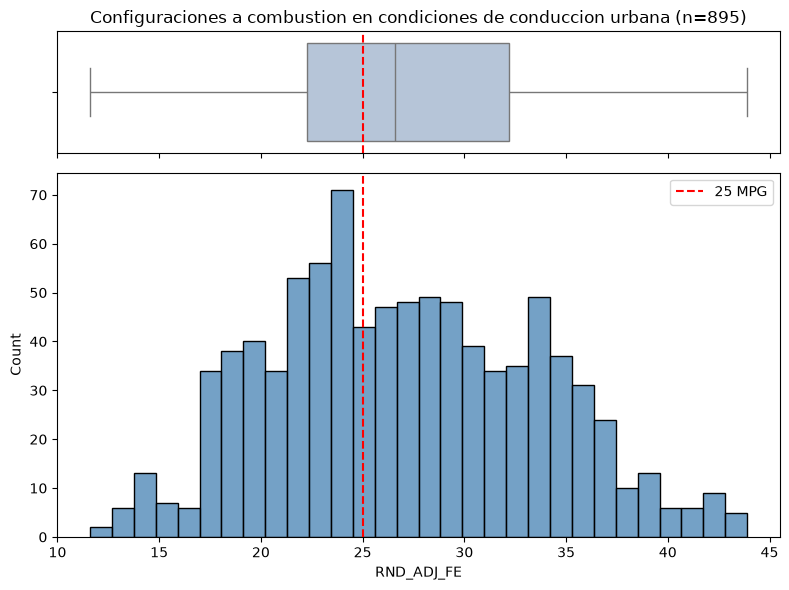

In [1540]:
d = unique_gasoline_configs

fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={"height_ratios": [1, 3]},
)

sns.boxplot(x=d["RND_ADJ_FE"], ax=ax_box, color="lightsteelblue")
ax_box.axvline(25, color="red", ls="--")
ax_box.set_title(f"Configuraciones a combustion en condiciones de conduccion urbana (n={len(d)})")
ax_box.set_xlabel("")

sns.histplot(d["RND_ADJ_FE"], bins=30, ax=ax_hist, color="steelblue")
ax_hist.axvline(25, color="red", ls="--", label="25 MPG")
ax_hist.legend()

plt.tight_layout()
plt.show()

### Ejecucion de tests

#### Supuesto de aproximacion de normalidad de test z

In [1541]:
n = len(d)    # Tamaño de la muestra
p0 = 0.5    # Proporción de la hipótesis nula (50%)

exitos_esperados = n * p0
fracasos_esperados = n * (1 - p0)

if exitos_esperados >= 10 and fracasos_esperados >= 10:
    print("Se cumple el supuesto de aproximacion de normalidad del test z")

Se cumple el supuesto de aproximacion de normalidad del test z


#### Ejecucion del test z y test binomial

In [1542]:
exitos = int((unique_gasoline_configs[COL] >= 25).sum())
n = len(d)
p_observado = exitos / n
print(f"El p-observado de la muestra es: {p_observado:.3f}")

z, p_value = proportions_ztest(exitos, n, value=0.5, alternative="larger", prop_var=0.5)

print(f"Z-Test. Estadistico: {z:.3f}. p-value: {p_value:.3f}")

p_exacto = binomtest(exitos, n, p=0.5, alternative="greater").pvalue

print(f"Binom-Test. Estadistico: {z:.3f}. p-value: {p_exacto:.3f}")

El p-observado de la muestra es: 0.577
Z-Test. Estadistico: 4.579. p-value: 0.000
Binom-Test. Estadistico: 4.579. p-value: 0.000


#### Intervalos de confianza

In [1543]:
alpha = 0.05

wilson = proportion_confint(exitos, n, alpha=alpha, method="wilson")
exacto = proportion_confint(exitos, n, alpha=alpha, method="beta")

print(f"p_hat = {exitos/n:.4f}")
print(f"IC {100*(1-alpha):g}% Wilson (z-test):   [{wilson[0]:.4f}, {wilson[1]:.4f}]")
print(f"IC {100*(1-alpha):g}% Exacto (binomial): [{exacto[0]:.4f}, {exacto[1]:.4f}]")

p_hat = 0.5765
IC 95% Wilson (z-test):   [0.5439, 0.6085]
IC 95% Exacto (binomial): [0.5434, 0.6092]


## Hipotesis 4b

### Graficos

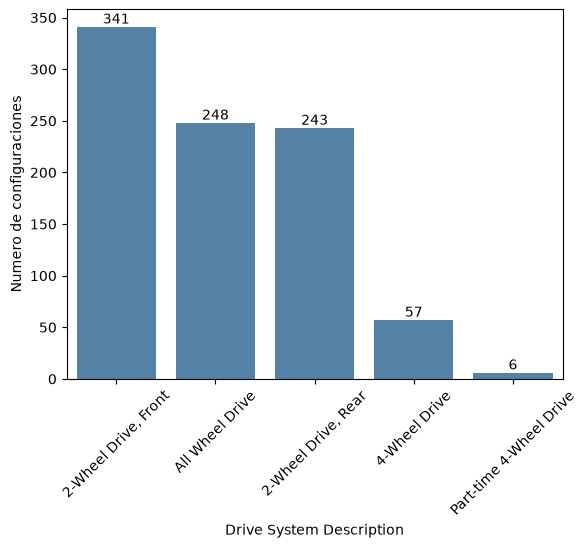

In [1544]:
orden_cat = unique_gasoline_configs["Drive System Description"].value_counts().index
ax = sns.countplot(data=unique_gasoline_configs, x="Drive System Description", order=orden_cat, color="steelblue")
ax.bar_label(ax.containers[0])
ax.set_ylabel("Numero de configuraciones")
plt.xticks(rotation=45)
plt.show()

In [1545]:
cat = "Part-time 4-Wheel Drive"
n_excl = (unique_gasoline_configs["Drive System Description"] == cat).sum()
pct_excl = n_excl / len(unique_gasoline_configs) * 100
print(f"Se excluyen {n_excl} filas ({pct_excl:.2f}%)")

# Eliminacion de filas
unique_gasoline_configs = unique_gasoline_configs[unique_gasoline_configs["Drive System Description"] != cat].reset_index(drop=True)

# Verificar eliminacion
print(unique_gasoline_configs["Drive System Description"].value_counts())

Se excluyen 6 filas (0.67%)
Drive System Description
2-Wheel Drive, Front    341
All Wheel Drive         248
2-Wheel Drive, Rear     243
4-Wheel Drive            57
Name: count, dtype: int64


                          count       mean  median       std   min    max
Drive System Description                                                 
2-Wheel Drive, Front        341  31.697801    31.8  5.327493  20.7  43.90
2-Wheel Drive, Rear         241  23.679668    23.0  5.343799  12.5  36.55
4-Wheel Drive                57  23.344737    21.0  6.385319  12.8  38.90
All Wheel Drive             248  24.795766    24.2  5.372116  11.6  35.30


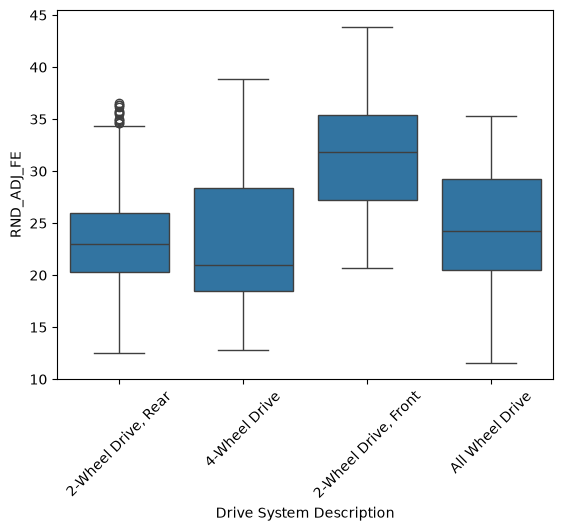

In [1546]:
x, y = "Drive System Description", "RND_ADJ_FE" 
print(unique_gasoline_configs.groupby(x)[y].agg(["count", "mean", "median", "std", "min", "max"]))
sns.boxplot(data=unique_gasoline_configs, x=x, y=y); plt.xticks(rotation=45); plt.show()

### Ejecucion de test sobre hipotesis original

#### Chequeo de supuestos

In [1547]:
modelo = smf.ols(f"RND_ADJ_FE ~ C(Q('Drive System Description'))", data=unique_gasoline_configs).fit()
resid = modelo.resid

##### Normalidad

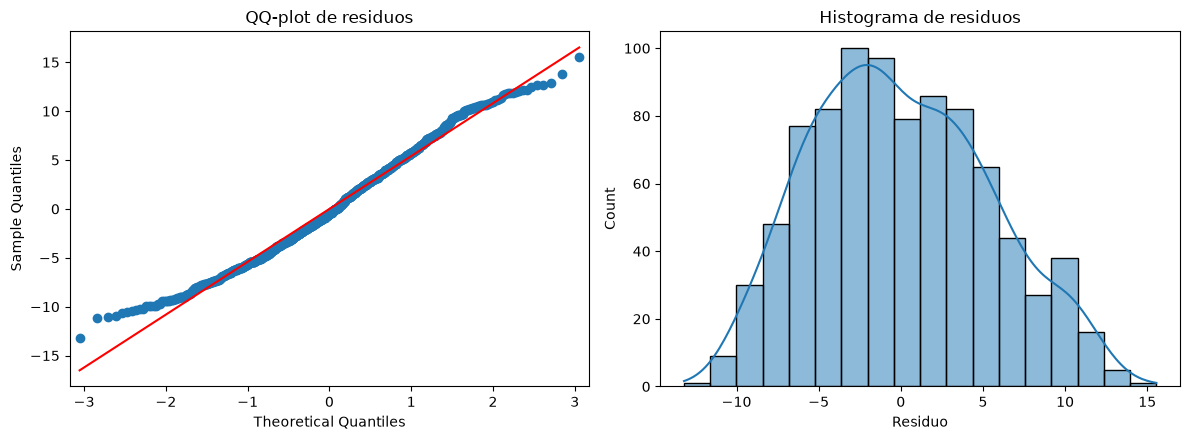

In [1548]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sm.qqplot(resid, line="s", ax=axes[0])
axes[0].set_title("QQ-plot de residuos")

sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title("Histograma de residuos")
axes[1].set_xlabel("Residuo")

plt.tight_layout()
plt.show()

In [1549]:
print(st.shapiro(resid))
print(f"Asimetría: {st.skew(resid):.3f} | Curtosis (exceso): {st.kurtosis(resid):.3f}")

ShapiroResult(statistic=np.float64(0.9865344873923969), pvalue=np.float64(2.8305499921230326e-07))
Asimetría: 0.254 | Curtosis (exceso): -0.589


In [1550]:
lil_stat, lil_p = lilliefors(resid, dist="norm", pvalmethod="approx")

print(f"Lilliefors: D = {lil_stat:.4f}, p = {lil_p:.4f}")


Lilliefors: D = 0.0447, p = 0.0003


##### Homocedasticidad

In [1551]:
grupos_resid_4b = [g.values for _, g in modelo.resid.groupby(unique_gasoline_configs["Drive System Description"])]

lev_stat, lev_p = st.levene(*grupos_resid_4b, center="median")
print(f"Levene: W = {lev_stat:.4f}, p = {lev_p:.4f}")

Levene: W = 2.7561, p = 0.0414


### Ejecucion de test sobre hipotesis alternativa

#### Test de Kruskal-Wallis

In [1552]:
grupos_mpg = [g["RND_ADJ_FE"].dropna().values
              for _, g in unique_gasoline_configs.groupby("Drive System Description")]
print(st.kruskal(*grupos_mpg))

KruskalResult(statistic=np.float64(284.3398748755163), pvalue=np.float64(2.436458535757969e-61))


#### Test de Dunn

In [1553]:
dunn = sp.posthoc_dunn(
    unique_gasoline_configs,
    val_col="RND_ADJ_FE",
    group_col="Drive System Description",
    p_adjust="holm"
)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(dunn.round(4))

                      2-Wheel Drive, Front  2-Wheel Drive, Rear  4-Wheel Drive  All Wheel Drive
2-Wheel Drive, Front                   1.0               0.0000         0.0000           0.0000
2-Wheel Drive, Rear                    0.0               1.0000         0.7432           0.0978
4-Wheel Drive                          0.0               0.7432         1.0000           0.2002
All Wheel Drive                        0.0               0.0978         0.2002           1.0000


##### Distribuciones de los sistemas de traccion

In [1554]:
print(unique_gasoline_configs.groupby(x)[y].agg(["count", "mean", "median", "std", "min", "max"]))

                          count       mean  median       std   min    max
Drive System Description                                                 
2-Wheel Drive, Front        341  31.697801    31.8  5.327493  20.7  43.90
2-Wheel Drive, Rear         241  23.679668    23.0  5.343799  12.5  36.55
4-Wheel Drive                57  23.344737    21.0  6.385319  12.8  38.90
All Wheel Drive             248  24.795766    24.2  5.372116  11.6  35.30


## Hipotesis 4c

In [1555]:
df_4c = unique_gasoline_configs.copy()

### Preprocesamiento

##### Procesamiento de variables cuantitativas

###### Eliminacion de valores nulos

In [1556]:
df_4c.isna().sum()

UID                              0
RND_ADJ_FE                       2
NOx (g/mi)                       0
Equivalent Test Weight (lbs.)    0
Rated Horsepower                 1
Test Veh Displacement (L)        0
# of Cylinders and Rotors        3
Tested Transmission Type         0
Drive System Description         0
dtype: int64

In [1557]:
df_4c = df_4c.dropna(subset=["RND_ADJ_FE", "# of Cylinders and Rotors", "Rated Horsepower"])

###### Analisis de multicolinealidad

In [1558]:
num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower",
       "Test Veh Displacement (L)", "# of Cylinders and Rotors"]
X_num = sm.add_constant(df_4c[num])
pd.Series([variance_inflation_factor(X_num.values, i) for i in range(1, X_num.shape[1])],
          index=num)

Equivalent Test Weight (lbs.)    1.507598
Rated Horsepower                 3.345111
Test Veh Displacement (L)        6.901459
# of Cylinders and Rotors        9.336105
dtype: float64

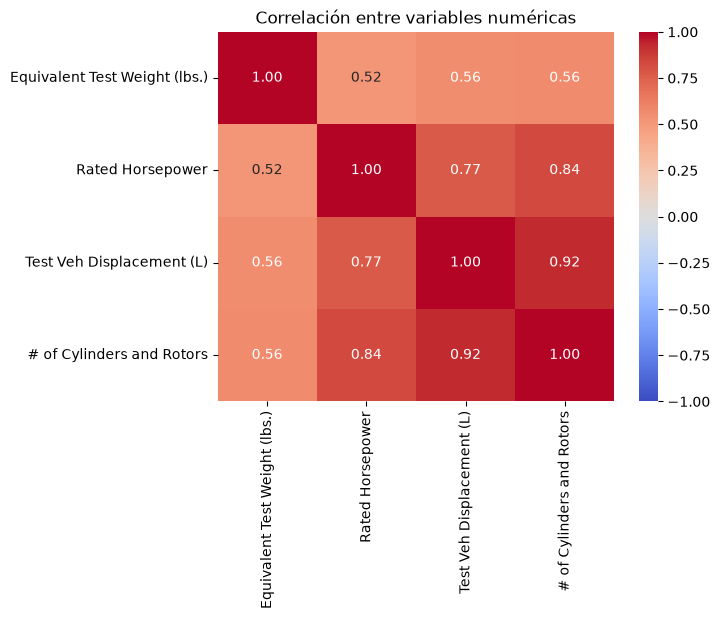

In [1559]:
corr = df_4c[num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

In [1560]:
num = ["Equivalent Test Weight (lbs.)", "Rated Horsepower",
       "Test Veh Displacement (L)"]

X_num = sm.add_constant(df_4c[num])
pd.Series([variance_inflation_factor(X_num.values, i) for i in range(1, X_num.shape[1])],
          index=num)

Equivalent Test Weight (lbs.)    1.499347
Rated Horsepower                 2.490079
Test Veh Displacement (L)        2.646593
dtype: float64

###### Estandarizacion

In [1561]:
scaler = StandardScaler()
num_std = pd.DataFrame(scaler.fit_transform(df_4c[num]),
                       columns=num,
                       index=df_4c.index)

##### Procesamiento de variables cualitativas

###### Reduccion de categorias en Transmision

In [1562]:
df_4c["Tested Transmission Type"].value_counts()

Tested Transmission Type
Semi-Automatic                                                       360
Automatic                                                            249
Automated Manual- Selectable (e.g. Automated Manual with paddles)    108
Selectable Continuously Variable (e.g. CVT with paddles)              60
Continuously Variable                                                 53
Manual                                                                39
Automated Manual                                                      14
Name: count, dtype: int64

In [1563]:
mapping = {
    "Semi-Automatic" : "Automatic",
    "Automated Manual- Selectable (e.g. Automated Manual with paddles)" : "Automated Manual",
    "Selectable Continuously Variable (e.g. CVT with paddles)" : "Continuously Variable"
}

df_4c["Tested Transmission Type"] = df_4c['Tested Transmission Type'].replace(mapping)
df_4c["Tested Transmission Type"].value_counts()


Tested Transmission Type
Automatic                609
Automated Manual         122
Continuously Variable    113
Manual                    39
Name: count, dtype: int64

###### Reduccion de categorias en Traccion

In [1564]:
df_4c["Drive System Description"].value_counts()

Drive System Description
2-Wheel Drive, Front    338
All Wheel Drive         248
2-Wheel Drive, Rear     240
4-Wheel Drive            57
Name: count, dtype: int64

In [1565]:
mapping = {
    "4-Wheel Drive" : "All Wheel Drive"
}

df_4c["Drive System Description"] = df_4c["Drive System Description"].replace(mapping)
df_4c["Drive System Description"].value_counts()

Drive System Description
2-Wheel Drive, Front    338
All Wheel Drive         305
2-Wheel Drive, Rear     240
Name: count, dtype: int64

###### Creacion de dummies de variables cualitativas

In [1566]:
dummies = pd.get_dummies(df_4c[["Tested Transmission Type", "Drive System Description"]],
                         prefix=["trans", "trac"], dtype=float)

dummies = dummies.drop(columns=["trans_Automatic", "trac_2-Wheel Drive, Front"])
dummies.columns

Index(['trans_Automated Manual', 'trans_Continuously Variable', 'trans_Manual', 'trac_2-Wheel Drive, Rear', 'trac_All Wheel Drive'], dtype='str')

### Ejecucion de test

In [1567]:
X = pd.concat([num_std, dummies], axis=1)
X = sm.add_constant(X)
y = df_4c["RND_ADJ_FE"]

print(X.isna().sum().sum())

modelo_std = sm.OLS(y, X).fit()
print(modelo_std.summary())

0
                            OLS Regression Results                            
Dep. Variable:             RND_ADJ_FE   R-squared:                       0.794
Model:                            OLS   Adj. R-squared:                  0.792
Method:                 Least Squares   F-statistic:                     420.5
Date:                Tue, 10 Nov 2026   Prob (F-statistic):          1.64e-293
Time:                        18:23:15   Log-Likelihood:                -2216.6
No. Observations:                 883   AIC:                             4451.
Df Residuals:                     874   BIC:                             4494.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const       

#### Chequeo de supuestos

##### Normalidad

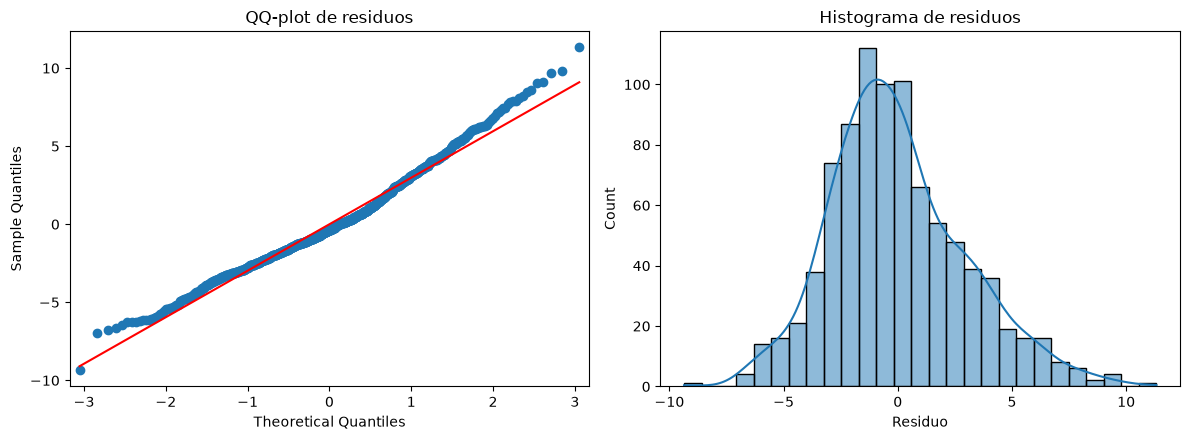

In [1568]:
resid = modelo_std.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sm.qqplot(resid, line="s", ax=axes[0])
axes[0].set_title("QQ-plot de residuos")

sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title("Histograma de residuos")
axes[1].set_xlabel("Residuo")

plt.tight_layout()
plt.show()

##### Homocedasticidad y Linealidad

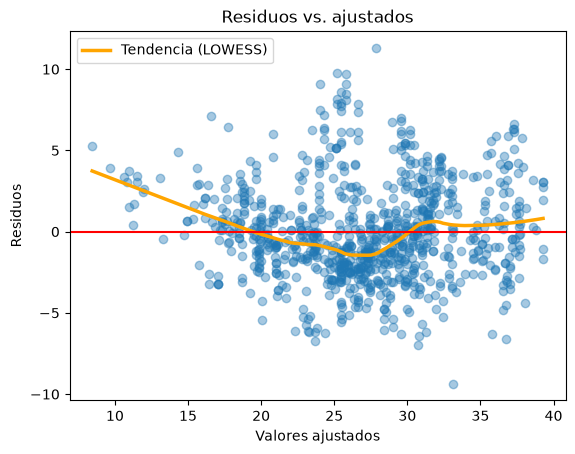

In [1569]:
ajustados = modelo_std.fittedvalues

suav = sm.nonparametric.lowess(resid, ajustados, frac=0.3)
plt.scatter(ajustados, resid, alpha=0.4)
plt.plot(suav[:, 0], suav[:, 1], color="orange", lw=2.5, label="Tendencia (LOWESS)")
plt.axhline(0, color="red")
plt.xlabel("Valores ajustados"); plt.ylabel("Residuos")
plt.title("Residuos vs. ajustados"); plt.legend(); plt.show()

In [1570]:
lm, lm_p, f, f_p = het_breuschpagan(resid, X)
print(f"Breusch-Pagan: LM = {lm:.2f}, p = {lm_p:.4g}")

Breusch-Pagan: LM = 46.77, p = 1.693e-07


##### Independencia

In [1571]:
orden = np.random.default_rng(0).permutation(len(resid))
print("DW orden original:", durbin_watson(resid))
print("DW orden aleatorio:", durbin_watson(resid.iloc[orden]))

DW orden original: 0.7751601474634319
DW orden aleatorio: 2.039320805455322


# Hipotesis de Grupo

## Hipotesis univariada

In [1572]:
hip_uni_prop = epa_cartest_uid[["UID","Tested Transmission Type"]].copy()
# retenemos las configuraciones unicas con su tipo de transmision
hip_uni_prop = hip_uni_prop.drop_duplicates()

hip_uni_prop["Tested Transmission Type"].value_counts()

Tested Transmission Type
Automatic                                                            643
Semi-Automatic                                                       404
Automated Manual- Selectable (e.g. Automated Manual with paddles)    142
Continuously Variable                                                134
Selectable Continuously Variable (e.g. CVT with paddles)              67
Manual                                                                42
Automated Manual                                                      16
Name: count, dtype: int64

### Preprocesamiento

In [1573]:
hip_uni_prop["pedal_embrague"] = hip_uni_prop["Tested Transmission Type"] == "Manual"
hip_uni_prop["pedal_embrague"].value_counts()

pedal_embrague
False    1406
True       42
Name: count, dtype: int64

### Grafico

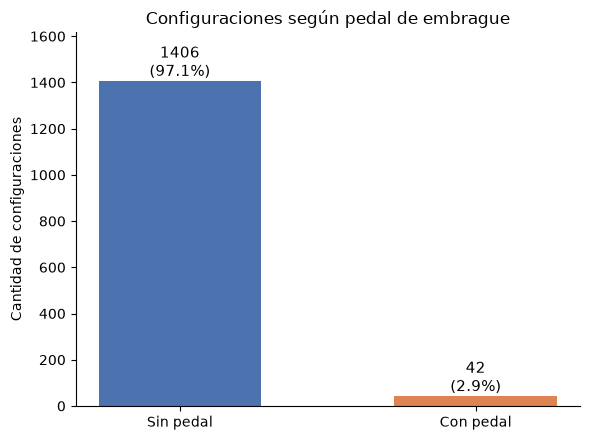

In [1574]:
conteo = hip_uni_prop["pedal_embrague"].map({False: "Sin pedal", True: "Con pedal"}).value_counts()
conteo = conteo[["Sin pedal", "Con pedal"]]
pct = conteo / conteo.sum()

fig, ax = plt.subplots(figsize=(6, 4.5))
barras = ax.bar(conteo.index, conteo.values, color=["#4C72B0", "#DD8452"], width=0.55)

for barra, n, p in zip(barras, conteo.values, pct.values):
    ax.text(barra.get_x() + barra.get_width() / 2, n, f"{n}\n({p:.1%})",
            ha="center", va="bottom", fontsize=11)

ax.set_title("Configuraciones según pedal de embrague")
ax.set_ylabel("Cantidad de configuraciones")
ax.set_ylim(0, conteo.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Ejecucion de tests

##### Test z para proporcion

###### Supuesto de aproximacion de normalidad de test z

In [1575]:
n = len(hip_uni_prop)    # Tamaño de la muestra
p0 = 0.9   # Proporción de la hipótesis nula (90%)

exitos_esperados = n * p0
fracasos_esperados = n * (1 - p0)

if exitos_esperados >= 10 and fracasos_esperados >= 10:
    print("Se cumple el supuesto de aproximacion de normalidad del test z")

Se cumple el supuesto de aproximacion de normalidad del test z


In [1576]:
k, n, p0 = 1406, 1448, 0.9 # k es el numero de exitos, p0 es la proporcion de la hipotesis nula H0
alpha = 0.001

z_estadistico, p_z = proportions_ztest(count=k, nobs=n, value=p0,
                                      alternative='larger', prop_var = p0)

print(f"Z-Test. Estadistico: {z_estadistico:.3f}. p-value: {p_z:.3f}")

Z-Test. Estadistico: 9.005. p-value: 0.000


##### Test Binomial

In [1577]:
res = binomtest(k, n, p=p0, alternative="greater")
print(f"Z-Test. Estadistico: {res.statistic:.3f}. p-value: {res.pvalue:.3f}")

Z-Test. Estadistico: 0.971. p-value: 0.000


#### Intervalo de Confianza

In [1578]:
# IC asociado al z-test: Wilson
wilson = proportion_confint(k, n, alpha=alpha, method="wilson")

# IC asociado al binomial: Clopper-Pearson (exacto)
exacto = proportion_confint(k, n, alpha=alpha, method="beta")

print(f"IC {100*(1-alpha):g}% Wilson (z-test):   [{wilson[0]:.4f}, {wilson[1]:.4f}]")
print(f"IC {100*(1-alpha):g}% Exacto (binomial): [{exacto[0]:.4f}, {exacto[1]:.4f}]")

IC 99.9% Wilson (z-test):   [0.9526, 0.9824]
IC 99.9% Exacto (binomial): [0.9535, 0.9834]


## Hipotesis bivariada

In [1579]:
hip_biv_prop = only_gasoline.copy()
hip_biv_prop["Test Procedure Description"].value_counts()

Test Procedure Description
HWFE                                          1058
Federal fuel 2-day exhaust (w/can load)        702
Federal fuel 3-day exhaust                     318
US06                                           258
SC03                                           124
CVS 75 and later (w/o can. load)                48
California fuel 2-day exhaust (w/can load)       5
Name: count, dtype: int64

#### Preprocesamiento

In [1580]:
tests = ["Federal fuel 2-day exhaust (w/can load)", "Federal fuel 3-day exhaust", "US06"]
hip_biv_prop = hip_biv_prop[hip_biv_prop["Test Procedure Description"].isin(tests)]
hip_biv_prop["Test Procedure Description"].value_counts()   

Test Procedure Description
Federal fuel 2-day exhaust (w/can load)    702
Federal fuel 3-day exhaust                 318
US06                                       258
Name: count, dtype: int64

In [1581]:
hip_biv_prop["Test Fuel Type Description"].value_counts()

Test Fuel Type Description
Tier 2 Cert Gasoline                             1224
Federal Cert Diesel 7-15 PPM Sulfur                45
E85 (85% Ethanol 15% EPA Unleaded Gasoline)         7
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       1
CARB LEV3 E10 Premium Gasoline                      1
Name: count, dtype: int64

In [1582]:
hip_biv_prop = hip_biv_prop[hip_biv_prop["Test Fuel Type Description"] == "Tier 2 Cert Gasoline"]

In [1583]:
hip_biv_prop["CO (g/mi)"].describe()

count    1224.000000
mean        0.414283
std         0.601846
min         0.026825
25%         0.166802
50%         0.270578
75%         0.477766
max        10.352100
Name: CO (g/mi), dtype: float64

In [1584]:
#colores
C2, C3, CM = "#4C78A8", "#E45756", "#555555"

# CO por vehículo (UID) en US06: mediana de sus runs
us06 = hip_biv_prop[hip_biv_prop["Test Procedure Description"] == "US06"].groupby("UID")["CO (g/mi)"].median().rename("US06")

def armar_pares(procs):
    # CO por vehículo en FTP (mediana de sus runs en los procedimientos indicados), unido con US06
    ftp = hip_biv_prop[hip_biv_prop["Test Procedure Description"].isin(procs)].groupby("UID")["CO (g/mi)"].median().rename("FTP")
    return pd.concat([ftp, us06], axis=1, join="inner")

grupos = {
    "FTP 2-day vs US06":         (armar_pares(["Federal fuel 2-day exhaust (w/can load)"]), C2),
    "FTP 3-day vs US06":         (armar_pares(["Federal fuel 3-day exhaust"]), C3),
    "FTP 2-day + 3-day vs US06": (armar_pares(["Federal fuel 2-day exhaust (w/can load)", "Federal fuel 3-day exhaust"]), CM),
}
{nombre: len(p) for nombre, (p, _) in grupos.items()}

{'FTP 2-day vs US06': 128,
 'FTP 3-day vs US06': 57,
 'FTP 2-day + 3-day vs US06': 185}

#### Grafico

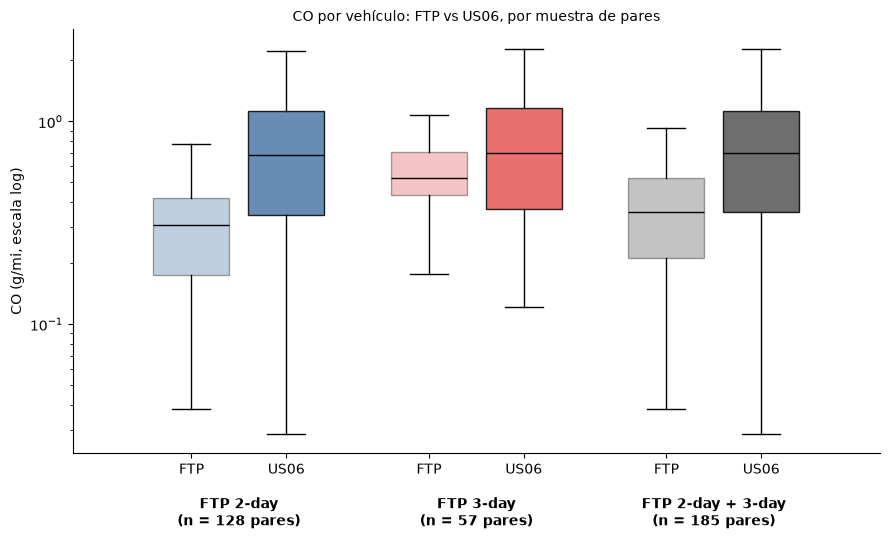

In [1585]:
fig, ax = plt.subplots(figsize=(9, 5.5))
pos, datos, cols, etiquetas = [], [], [], []
for i, (nombre, (p, col)) in enumerate(grupos.items()):
    for off, cond in [(-.2, "FTP"), (.2, "US06")]:
        pos.append(i + off); datos.append(p[cond]); cols.append(col)
        etiquetas.append(cond)                                   # <- NUEVO: una etiqueta por caja

bp = ax.boxplot(datos, positions=pos, widths=.32, patch_artist=True, showfliers=False)
for k, (patch, col) in enumerate(zip(bp["boxes"], cols)):
    patch.set_facecolor(col); patch.set_alpha(.35 if k % 2 == 0 else .85)
for med in bp["medians"]: med.set_color("k")

# Marcas del eje x en la posición de cada caja, con "FTP" / "US06"
ax.set_xticks(pos)
ax.set_xticklabels(etiquetas)

# NUEVO: nombre del grupo (y n) debajo, centrado entre sus dos cajas
for i, (nombre, (p, _)) in enumerate(grupos.items()):
    ax.text(i, -0.10, f"{nombre.replace(' vs US06','')}\n(n = {len(p)} pares)",
            transform=ax.get_xaxis_transform(), ha="center", va="top",
            fontsize=10, fontweight="bold")

ax.set_yscale("log"); ax.set_ylabel("CO (g/mi, escala log)")
ax.set_title("CO por vehículo: FTP vs US06, por muestra de pares", fontsize=10)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

In [1586]:
df_2day3day = grupos["FTP 2-day + 3-day vs US06"][0]
df_2day = grupos["FTP 2-day vs US06"][0]

### Ejecucion de tests

#### Chequeo de supuestos de test t

In [1587]:
def difs(p):
    return p["US06"] - p["FTP"], np.log(p["US06"]) - np.log(p["FTP"])   # (cruda, en log)

In [1588]:
filas = {}
for nombre, (p, _) in grupos.items():
    d, ld = difs(p)
    filas[nombre] = {
        "n": len(p),
        "asimetría cruda": st.skew(d),   "curtosis cruda": st.kurtosis(d),
        "Shapiro p (crudo)": st.shapiro(d).pvalue,
        "asimetría log": st.skew(ld),    "curtosis log": st.kurtosis(ld),
        "Shapiro p (log)": st.shapiro(ld).pvalue,
        "outliers crudos (|z|>3)": int((abs((d - d.mean()) / d.std()) > 3).sum()),
    }
pd.DataFrame(filas).T

,n,asimetría cruda,curtosis cruda,Shapiro p (crudo),asimetría log,curtosis log,Shapiro p (log),outliers crudos (|z|>3)
FTP 2-day vs US06,128.0,4.212039,21.605237,6.284971e-18,0.419774,-0.012257,0.130946,2.0
FTP 3-day vs US06,57.0,3.415879,15.488544,5.483645e-10,0.344155,0.279233,0.229643,1.0
FTP 2-day + 3-day vs US06,185.0,4.441679,25.394520,2.721571e-21,0.440299,0.127145,0.029254,5.0


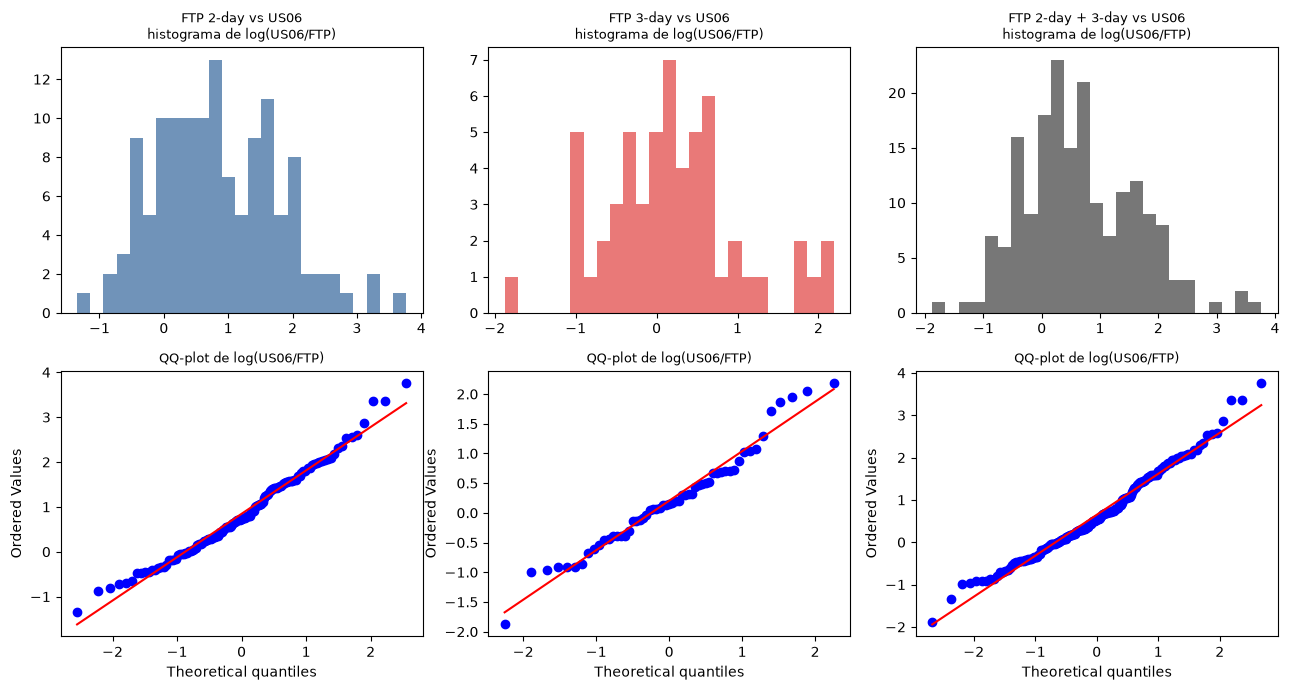

In [1589]:
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for j, (nombre, (p, col)) in enumerate(grupos.items()):
    d, ld = difs(p)
    ax[0, j].hist(ld, bins=25, color=col, alpha=.8)
    ax[0, j].set_title(f"{nombre}\nhistograma de log(US06/FTP)", fontsize=9)
    st.probplot(ld, dist="norm", plot=ax[1, j])
    ax[1, j].set_title("QQ-plot de log(US06/FTP)", fontsize=9)
plt.tight_layout(); plt.show()

#### Test t para muestras apareadas

In [1590]:
filas = {}
for nombre, (p, _) in grupos.items():
    lf, lu = np.log(p["FTP"]), np.log(p["US06"])
    t, pval = st.ttest_rel(lu, lf)                 # bilateral: H1 es "distinto"
    ld = lu - lf; n = len(ld)
    se = ld.std(ddof=1) / np.sqrt(n); tc = st.t.ppf(.975, n - 1)
    filas[nombre] = {"n": n, "t": t, "gl": n - 1, "p-valor": pval,
                     "cociente medio US06/FTP": np.exp(ld.mean()),
                     "IC95 inf": np.exp(ld.mean() - tc * se),
                     "IC95 sup": np.exp(ld.mean() + tc * se)}
pd.DataFrame(filas).T

,n,t,gl,p-valor,cociente medio US06/FTP,IC95 inf,IC95 sup
FTP 2-day vs US06,128.0,9.943109,127.0,1.401008e-17,2.331017,1.969694,2.758622
FTP 3-day vs US06,57.0,1.866557,56.0,6.720250e-02,1.226513,0.985160,1.526995
FTP 2-day + 3-day vs US06,185.0,9.116623,184.0,1.332767e-16,1.912592,1.662172,2.200739


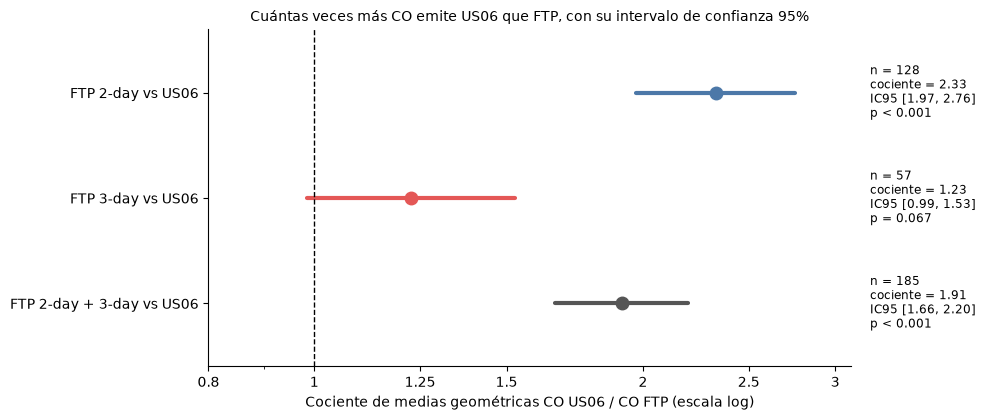

In [1591]:
# 1) Resultados del t apareado sobre log(CO) para cada muestra
res = []
for nombre, (p, col) in grupos.items():
    ld = np.log(p["US06"]) - np.log(p["FTP"])          # diferencia en log por vehículo
    n = len(ld)
    t, pval = st.ttest_rel(np.log(p["US06"]), np.log(p["FTP"]))
    se = ld.std(ddof=1) / np.sqrt(n)                    # error estándar
    tc = st.t.ppf(0.975, n - 1)                      # valor crítico para IC95
    res.append({"nombre": nombre, "n": n, "color": col, "pval": pval,
                "ratio": np.exp(ld.mean()),
                "lo": np.exp(ld.mean() - tc * se),
                "hi": np.exp(ld.mean() + tc * se)})

# 2) Gráfico: cociente US06/FTP e IC95% por muestra
fig, ax = plt.subplots(figsize=(10, 4.3))
for i, r in enumerate(res):
    y = len(res) - 1 - i
    ax.plot([r["lo"], r["hi"]], [y, y], color=r["color"], lw=3, solid_capstyle="round")   # intervalo
    ax.plot(r["ratio"], y, "o", color=r["color"], ms=9, zorder=3)                         # estimación
    ptxt = "p < 0.001" if r["pval"] < 0.001 else f"p = {r['pval']:.3f}"
    ax.text(1.03, y, f"n = {r['n']}\ncociente = {r['ratio']:.2f}\nIC95 [{r['lo']:.2f}, {r['hi']:.2f}]\n{ptxt}",
            transform=ax.get_yaxis_transform(), va="center", fontsize=8.5)

ax.axvline(1, color="k", ls="--", lw=1)                       # 1 = sin efecto
ax.set_xscale("log")
ticks = [0.8, 1, 1.25, 1.5, 2, 2.5, 3]
ax.set_xticks(ticks); ax.set_xticklabels([str(t) for t in ticks])
ax.set_xlim(0.8, 3.1); ax.set_ylim(-.6, len(res) - .4)
ax.set_yticks(range(len(res))); ax.set_yticklabels([r["nombre"] for r in res][::-1])
ax.set_xlabel("Cociente de medias geométricas CO US06 / CO FTP (escala log)")
ax.set_title("Cuántas veces más CO emite US06 que FTP, con su intervalo de confianza 95%", fontsize=10)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

#### Test de Wilcoxon

In [1592]:
for nombre, (p, _) in grupos.items():
    ld = np.log(p["US06"]) - np.log(p["FTP"])
    w = st.wilcoxon(np.log(p["US06"]), np.log(p["FTP"]))
    print(f"{nombre}: n = {len(ld)}, W = {w.statistic:.0f}, p = {w.pvalue:.3g}, "
          f"cociente mediano US06/FTP = {np.exp(np.median(ld)):.2f}")

FTP 2-day vs US06: n = 128, W = 851, p = 6.53e-15, cociente mediano US06/FTP = 2.07
FTP 3-day vs US06: n = 57, W = 617, p = 0.096, cociente mediano US06/FTP = 1.17
FTP 2-day + 3-day vs US06: n = 185, W = 2981, p = 1.28e-14, cociente mediano US06/FTP = 1.72


## Hipotesis multivariada

In [1593]:
multi_hip = only_gasoline.copy()
multi_hip["Test Fuel Type Description"].value_counts()

Test Fuel Type Description
Tier 2 Cert Gasoline                             2354
Federal Cert Diesel 7-15 PPM Sulfur               141
E85 (85% Ethanol 15% EPA Unleaded Gasoline)        12
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.)       3
CARB LEV3 E10 Premium Gasoline                      2
CARB LEV3 E10 Regular Gasoline                      1
Name: count, dtype: int64

### Preprocesamiento

In [1594]:
#me quedo con el combustible de referencia
multi_hip = multi_hip[multi_hip["Test Fuel Type Description"] == "Tier 2 Cert Gasoline"]

fe_us06 = (multi_hip[multi_hip["Test Category"] == "US06"]
           .groupby("UID")["RND_ADJ_FE"].median())
fe_ftp  = (multi_hip[multi_hip["Test Category"] == "FTP"]
           .groupby("UID")["RND_ADJ_FE"].median())

print(f"Configuraciones con US06: {len(fe_us06)}")
print(f"Configuraciones con FTP:  {len(fe_ftp)}")

Configuraciones con US06: 186
Configuraciones con FTP:  877


In [1595]:
cociente_us06 = (fe_us06 / fe_ftp).dropna()
y_us06 = np.log(cociente_us06).rename("log_cociente_us06")

print(f"Configuraciones con ambos ensayos: {len(y_us06)}")
print(cociente_us06.describe())

Configuraciones con ambos ensayos: 185
count    185.000000
mean       0.935665
std        0.145592
min        0.720988
25%        0.837398
50%        0.900474
75%        0.989547
max        1.454545
Name: RND_ADJ_FE, dtype: float64


In [1596]:
W, H, D = "Equivalent Test Weight (lbs.)", "Rated Horsepower", "Test Veh Displacement (L)"
T, R = "Tested Transmission Type", "Drive System Description"

atributos_us06 = multi_hip.groupby("UID")[[W, H, D, T, R]].first()

df_us06 = atributos_us06.join(y_us06, how="inner")

# Mapping de reduccion de sistemas de transmision (igual que en 4c)
df_us06[T] = df_us06[T].replace({
    "Semi-Automatic": "Automatic",
    "Automated Manual- Selectable (e.g. Automated Manual with paddles)": "Automated Manual",
    "Selectable Continuously Variable (e.g. CVT with paddles)": "Continuously Variable",
})

# Mapping de reduccion de sistemas de traccion (igual que en 4c)
df_us06[R] = df_us06[R].replace({"4-Wheel Drive": "All Wheel Drive"})

# Eliminacion de categoria por n pequeño (igual que en 4b)
df_us06 = df_us06[df_us06[R] != "Part-time 4-Wheel Drive"]

In [1597]:
df_us06 = df_us06[df_us06[H] >= 80] #se eliminan los vehiculos que tienen Na
print(f"n final: {len(df_us06)}")

n final: 183


In [1598]:
X_num_us06 = pd.DataFrame({
    "ln_peso":       np.log(df_us06[W]),
    "ln_hp":         np.log(df_us06[H]),
    "ln_cilindrada": np.log(df_us06[D]),
}, index=df_us06.index)

dummies_us06 = pd.get_dummies(df_us06[[T, R]], prefix=["trans", "trac"], dtype=float)
dummies_us06 = dummies_us06.drop(columns=["trans_Automatic", "trac_2-Wheel Drive, Front"])

X_us06 = sm.add_constant(pd.concat([X_num_us06, dummies_us06], axis=1))
y_us06 = df_us06["log_cociente_us06"]

#### Ejecucion de test de regresion lineal

In [1599]:
modelo_us06 = sm.OLS(y_us06, X_us06).fit()
print(modelo_us06.summary())

                            OLS Regression Results                            
Dep. Variable:      log_cociente_us06   R-squared:                       0.834
Model:                            OLS   Adj. R-squared:                  0.826
Method:                 Least Squares   F-statistic:                     109.3
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           9.39e-64
Time:                        18:23:17   Log-Likelihood:                 258.28
No. Observations:                 183   AIC:                            -498.6
Df Residuals:                     174   BIC:                            -469.7
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

##### Chequeo de supuestos

###### Normalidad

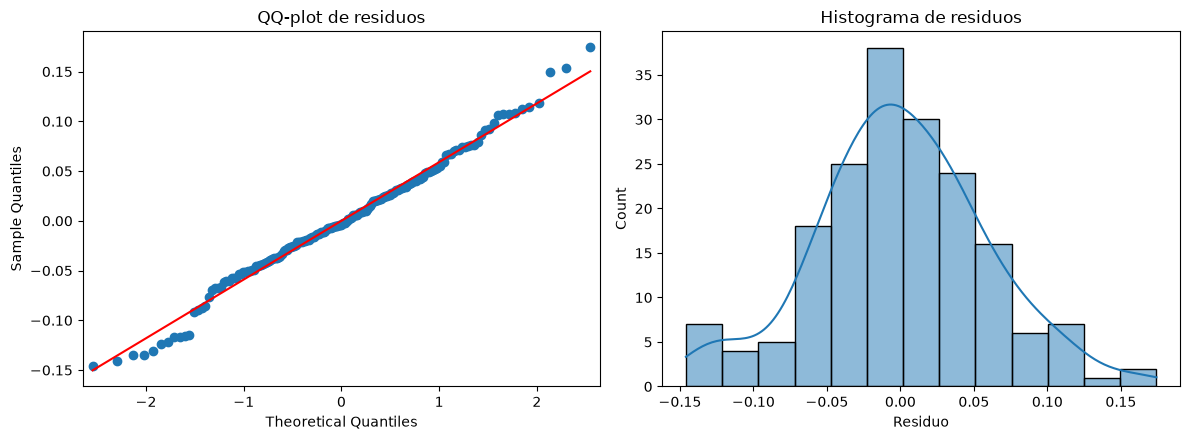

In [1600]:
resid_us06 = modelo_us06.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sm.qqplot(resid_us06, line="s", ax=axes[0])
axes[0].set_title("QQ-plot de residuos")

sns.histplot(resid_us06, kde=True, ax=axes[1])
axes[1].set_title("Histograma de residuos")
axes[1].set_xlabel("Residuo")

plt.tight_layout()
plt.show()

###### VIF

In [1601]:
print(pd.Series([variance_inflation_factor(X_us06.values, i) for i in range(1, X_us06.shape[1])],
                index=X_us06.columns[1:]).round(2))

ln_peso                        2.43
ln_hp                          5.67
ln_cilindrada                  4.28
trans_Automated Manual         1.26
trans_Continuously Variable    1.75
trans_Manual                   1.09
trac_2-Wheel Drive, Rear       3.10
trac_All Wheel Drive           2.84
dtype: float64


###### Homocedasticidad y Linealidad

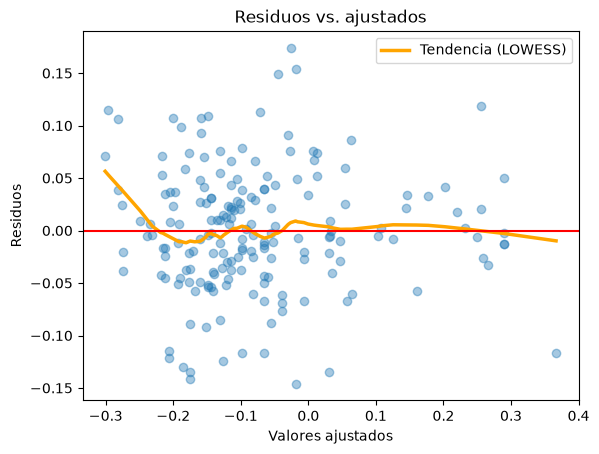

In [1602]:
ajust_us06 = modelo_us06.fittedvalues

suav = sm.nonparametric.lowess(resid_us06, ajust_us06, frac=0.3)
plt.scatter(ajust_us06, resid_us06, alpha=0.4)
plt.plot(suav[:, 0], suav[:, 1], color="orange", lw=2.5, label="Tendencia (LOWESS)")
plt.axhline(0, color="red")
plt.xlabel("Valores ajustados"); plt.ylabel("Residuos")
plt.title("Residuos vs. ajustados"); plt.legend(); plt.show()

In [1603]:
lm, lm_p, f, f_p = het_breuschpagan(resid_us06, X_us06)
print(f"Breusch-Pagan: LM = {lm:.2f}, p = {lm_p:.4g}")

Breusch-Pagan: LM = 14.89, p = 0.06142


In [1604]:
orden = np.random.default_rng(0).permutation(len(resid_us06))
print("DW orden original:", durbin_watson(resid_us06))
print("DW orden aleatorio:", durbin_watson(resid_us06.iloc[orden]))

DW orden original: 1.4572738411523674
DW orden aleatorio: 1.8542929641811288
